 # Freshness Classification Using Deep Learning

## Data Preprocessing

In [ ]:
# ==============================================================================
# 1. ENVIRONMENT SETUP & REPRODUCIBILITY
# ==============================================================================

# File and directory management
import os
import shutil
import random

# Data handling and visualization
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

# Deep Learning framework and utilities
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import SGD, RMSprop, Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

# Pre-trained models and specialized preprocessing
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_preprocess
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix
# Mount Google Drive to save the best model checkpoints
drive.mount('/content/drive')

# Set global seeds to ensure strict reproducibility across runs
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Force TensorFlow to use deterministic operations on GPU
tf.config.experimental.enable_op_determinism()



Mounted at /content/drive


In [ ]:
# ==============================================================================
# 2. DATA DOWNLOAD & EXTRACTION (KAGGLEHUB)
# ==============================================================================
import kagglehub

# Download the latest version of the fruits and vegetables dataset
path = kagglehub.dataset_download("muhriddinmuxiddinov/fruits-and-vegetables-dataset")
print("Dataset downloaded to:", path)

# Define the base path containing the specific image folders
base_path = os.path.join(path, 'Fruits_Vegetables_Dataset(12000)')

# ==============================================================================
# 3. CONSOLIDATING ALL CLASSES INTO A SINGLE DIRECTORY
# ==============================================================================
# Define a target directory to merge both Fruits and Vegetables classes
data_path = '/content/data/all_classes'
os.makedirs(data_path, exist_ok=True)

# Loop through both structural categories and copy classes to the unified folder
for group in ['Fruits', 'Vegetables']:
    group_path = os.path.join(base_path, group)

    for cls in os.listdir(group_path):
        src = os.path.join(group_path, cls)
        dst = os.path.join(data_path, cls)

        if os.path.isdir(src):
            # Copy the entire directory tree if it exists
            shutil.copytree(src, dst, dirs_exist_ok=True)

# Retrieve and print the consolidated class names
classes = sorted(os.listdir(data_path))   # ✅
print("Consolidated Classes:", classes)
print("Total number of classes:", len(classes))

Using Colab cache for faster access to the 'fruits-and-vegetables-dataset' dataset.
Dataset downloaded to: /kaggle/input/fruits-and-vegetables-dataset
Consolidated Classes: ['FreshApple', 'FreshBanana', 'FreshBellpepper', 'FreshCarrot', 'FreshCucumber', 'FreshMango', 'FreshOrange', 'FreshPotato', 'FreshStrawberry', 'FreshTomato', 'RottenApple', 'RottenBanana', 'RottenBellpepper', 'RottenCarrot', 'RottenCucumber', 'RottenMango', 'RottenOrange', 'RottenPotato', 'RottenStrawberry', 'RottenTomato']
Total number of classes: 20


In [ ]:
# ==============================================================================
# 4. DATA QUALITY CHECK & VERIFICATION
# ==============================================================================

# Count and display the number of images per class
for cls in classes:
    class_path = os.path.join(data_path, cls)
    if os.path.isdir(class_path):
        print(f"{cls}: {len(os.listdir(class_path))} images")

# Verify image integrity to detect and remove corrupted files
bad_images = []
for cls in classes:
    class_path = os.path.join(data_path, cls)
    if os.path.isdir(class_path):
        for file in os.listdir(class_path):
            img_path = os.path.join(class_path, file)
            try:
                img = Image.open(img_path)
                img.verify() # Verify if the file is a valid image
            except:
                bad_images.append(img_path)

print("Total number of corrupted images found:", len(bad_images))

# Inspect the color mode of a sample image (e.g., RGB)
sample_class = sorted(os.listdir(data_path))[0]  # ✅
sample_image = os.listdir(os.path.join(data_path, sample_class))[0]
img_path = os.path.join(data_path, sample_class, sample_image)
img = Image.open(img_path)
print(f"Sample Image Color Mode: {img.mode}")

# ==============================================================================
# 5. DETERMINISTIC DATASET SPLITTING (70% Train, 15% Val, 15% Test)
# ==============================================================================
output_path = '/content/data/splitted_data'
train_path = os.path.join(output_path, 'train')
val_path = os.path.join(output_path, 'val')
test_path = os.path.join(output_path, 'test')

# Create necessary directories for the splits
for folder in [train_path, val_path, test_path]:
    os.makedirs(folder, exist_ok=True)

random.seed(42)  # ✅


for cls in classes:
    class_path = os.path.join(data_path, cls)

    if os.path.isdir(class_path):
        # Using sorted() ensures consistent file ordering across different OS platforms
        images = sorted(os.listdir(class_path))

        # Reset the seed inside the loop to ensure identical shuffling order every run
        #random.seed(42)
        random.shuffle(images)

        total = len(images)
        train_count = int(total * 0.70)
        val_count = int(total * 0.15)

        # Split the files into respective lists
        train_images = images[:train_count]
        val_images = images[train_count:train_count + val_count]
        test_images = images[train_count + val_count:]

        # Create subdirectories for the current class in train/val/test folders
        os.makedirs(os.path.join(train_path, cls), exist_ok=True)
        os.makedirs(os.path.join(val_path, cls), exist_ok=True)
        os.makedirs(os.path.join(test_path, cls), exist_ok=True)

        # Copy files to their corresponding destinations
        for img in train_images:
            shutil.copy(os.path.join(class_path, img), os.path.join(train_path, cls, img))
        for img in val_images:
            shutil.copy(os.path.join(class_path, img), os.path.join(val_path, cls, img))
        for img in test_images:
            shutil.copy(os.path.join(class_path, img), os.path.join(test_path, cls, img))

print("Dataset splitting successfully completed.")

FreshApple: 612 images
FreshBanana: 624 images
FreshBellpepper: 611 images
FreshCarrot: 620 images
FreshCucumber: 608 images
FreshMango: 605 images
FreshOrange: 609 images
FreshPotato: 615 images
FreshStrawberry: 603 images
FreshTomato: 604 images
RottenApple: 588 images
RottenBanana: 576 images
RottenBellpepper: 591 images
RottenCarrot: 580 images
RottenCucumber: 593 images
RottenMango: 593 images
RottenOrange: 591 images
RottenPotato: 585 images
RottenStrawberry: 596 images
RottenTomato: 596 images
Total number of corrupted images found: 0
Sample Image Color Mode: RGB
Dataset splitting successfully completed.


Found 8383 files belonging to 20 classes.
Found 1787 files belonging to 20 classes.
Found 1816 files belonging to 20 classes.


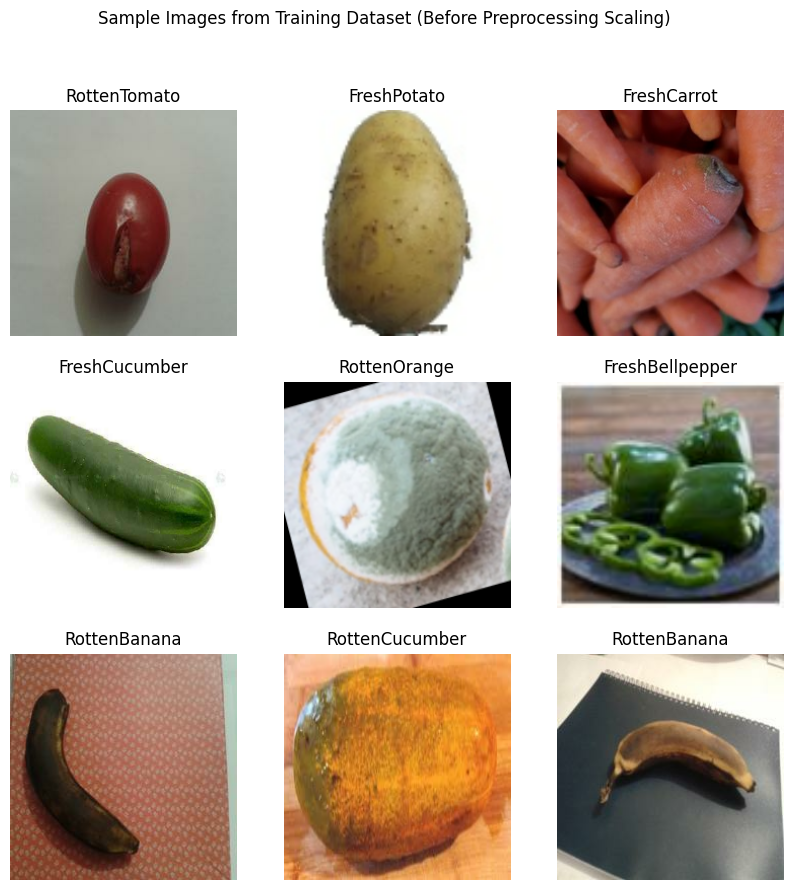

In [ ]:
# ==============================================================================
# 6. MODERN DATA LOADING & PREPROCESSING
# ==============================================================================

# Standard image parameters
BATCH_SIZE = 32
IMG_SIZE = (224, 224)

# Load Training Dataset directly from directory
train_gen = tf.keras.utils.image_dataset_from_directory(
    '/content/data/splitted_data/train',
    labels='inferred',
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True,
    seed=42 # Ensures exact reproducibility of batch order
)

# Load Validation Dataset directly from directory
val_gen = tf.keras.utils.image_dataset_from_directory(
    '/content/data/splitted_data/val',
    labels='inferred',
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

# Load Test Dataset directly from directory
test_gen = tf.keras.utils.image_dataset_from_directory(
    '/content/data/splitted_data/test',
    labels='inferred',
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

# ------------------------------------------------------------------------------
#  DISPLAY RANDOM SAMPLES FROM THE TRAINING DATASET
# ------------------------------------------------------------------------------
# Get class names from the dataset structure
class_names = train_gen.class_names

plt.figure(figsize=(10, 10))
# Take one batch from the training dataset to visualize original images
for images, labels in train_gen.take(1):
    for i in range(9): # Display the first 9 images from the batch
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        # Get the index of the active class (where label == 1)
        class_idx = np.argmax(labels[i])
        plt.title(class_names[class_idx])
        plt.axis("off")
plt.suptitle("Sample Images from Training Dataset (Before Preprocessing Scaling)")
plt.show()

# ------------------------------------------------------------------------------
# AUTOMATIC PROCESS & NORMALIZE (VIA MAP FUNCTION)
# ------------------------------------------------------------------------------
# Apply EfficientNet preprocessing function directly to the datasets via mapping
# This automatically normalizes/scales pixel values specifically for EfficientNetB0
train_gen = train_gen.map(lambda x, y: (effnet_preprocess(x), y))
val_gen = val_gen.map(lambda x, y: (effnet_preprocess(x), y))
test_gen = test_gen.map(lambda x, y: (effnet_preprocess(x), y))

In [ ]:
# Number of output classes
num_classes = len(classes)
print("Number of classes:", num_classes)

Number of classes: 20


## Baseline Model

**Baseline Hyperparameters**

1. **Model:** `EfficientNet-B0 (Pre-trained on ImageNet)`
2. **Input Size:** `224 x 224 x 3`
3. **Optimizer:** `Adam`
4. **Initial Learning Rate:** `0.001`
5. **Loss Function:** `Categorical Cross-Entropy`
6. **Batch Size:** `32`
7. **Dropout Rate:** `0.2`

In [ ]:
# ==============================================================================
# 7. BASELINE MODEL BUILDING, TRAINING & EVALUATION
# ==============================================================================

# Define the baseline model creation function exactly as requested
def create_effnetb0_baseline(num_classes, input_shape=(224, 224, 3)):
    # Load pretrained EfficientNetB0
    # include_top=False removes the original classifier head
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )

    # Freeze the base model to prevent training
    base_model.trainable = False

    # Build classification head
    model = models.Sequential([
        base_model,                         # feature extractor
        layers.GlobalAveragePooling2D(),    # convert features to vector
        layers.Dropout(0.2),                # reduce overfitting
        layers.Dense(num_classes, activation="softmax")  # output layer
    ])

    return model

In [ ]:
# Create Model Instance
model = create_effnetb0_baseline(num_classes)

# Print model architecture summary
model.summary()

# Compile model with Adam optimizer and Categorical Crossentropy loss
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the model (using 10 epochs as specified)
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

# Save trained model to Google Drive
model.save("/content/drive/MyDrive/effnetb0_baseline_model.keras")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 45s 120ms/step - accuracy: 0.8101 - loss: 0.7877 - val_accuracy: 0.9273 - val_loss: 0.3165
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - accuracy: 0.9367 - loss: 0.2602 - val_accuracy: 0.9496 - val_loss: 0.2108
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - accuracy: 0.9540 - loss: 0.1857 - val_accuracy: 0.9558 - val_loss: 0.1719
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 111ms/step - accuracy: 0.9633 - loss: 0.1452 - val_accuracy: 0.9614 - val_loss: 0.1488
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 33s 128ms/step - accuracy: 0.9693 - loss: 0.1206 - val_accuracy: 0.9603 - val_loss: 0.1363
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 37s 113ms/step - accuracy: 0.9748 - loss: 0.1033 - val_accuracy: 0.9625 - val_loss: 0.1288
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 111ms/step - accuracy: 0.9772 - loss: 0.0911 - val_accuracy: 0.9647 - val_loss: 0.1187
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 111ms/step - accuracy: 0.9827 - loss: 0

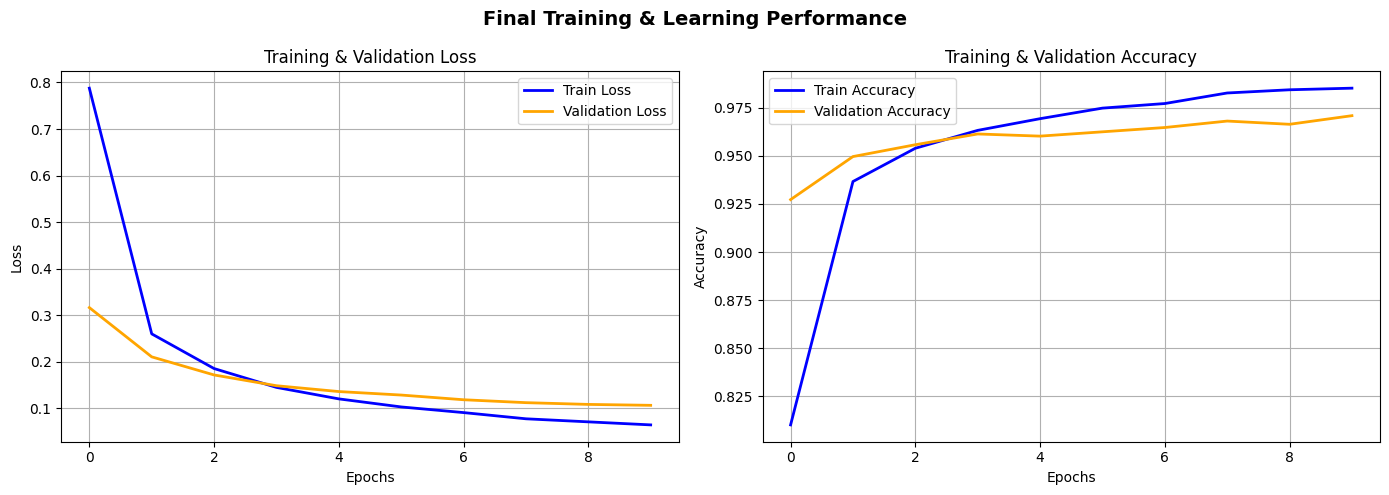

In [ ]:
# ------------------------------------------------------------------------------
# TRAINING PERFORMANCE VISUALIZATION (ACCURACY & LOSS - SIDE BY SIDE)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Loss Curves (Train vs Validation)
axes[0].plot(history.history['loss'], label='Train Loss', color='blue', lw=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='orange', lw=2)
axes[0].set_title('Training & Validation Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# 2. Accuracy Curves (Train vs Validation)
axes[1].plot(history.history['accuracy'], label='Train Accuracy', color='blue', lw=2)
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', lw=2)
axes[1].set_title('Training & Validation Accuracy')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Final Training & Learning Performance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# 8. MODEL EVALUATION (CLASSIFICATION REPORT & CONFUSION MATRIX)
# ==============================================================================
def evaluate(model_path, dataset, class_names):
    # 1. Load Saved Model
    model = tf.keras.models.load_model(model_path)

    # 2. Extract True Labels and Model Predictions safely from dataset
    y_true = []
    y_pred = []

    print("Evaluating model and generating predictions...")
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(np.argmax(labels.numpy(), axis=1))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # 3. Print Classification Report
    print("\n" + "="*60 + "\nClassification Report:\n" + "="*60)
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # 4. Plot Confusion Matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Greens',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix - Validation Set')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


Evaluating model and generating predictions...

Classification Report:
                  precision    recall  f1-score   support

      FreshApple     0.9889    0.9780    0.9834        91
     FreshBanana     1.0000    1.0000    1.0000        93
 FreshBellpepper     0.9368    0.9780    0.9570        91
     FreshCarrot     0.9479    0.9785    0.9630        93
   FreshCucumber     0.9891    1.0000    0.9945        91
      FreshMango     0.9890    1.0000    0.9945        90
     FreshOrange     0.9677    0.9890    0.9783        91
     FreshPotato     0.9785    0.9891    0.9838        92
 FreshStrawberry     1.0000    0.9889    0.9944        90
     FreshTomato     1.0000    0.9667    0.9831        90
     RottenApple     0.9419    0.9310    0.9364        87
    RottenBanana     1.0000    0.9884    0.9942        86
RottenBellpepper     0.9432    0.9432    0.9432        88
    RottenCarrot     0.9756    0.9302    0.9524        86
  RottenCucumber     0.9551    0.9659    0.9605        88


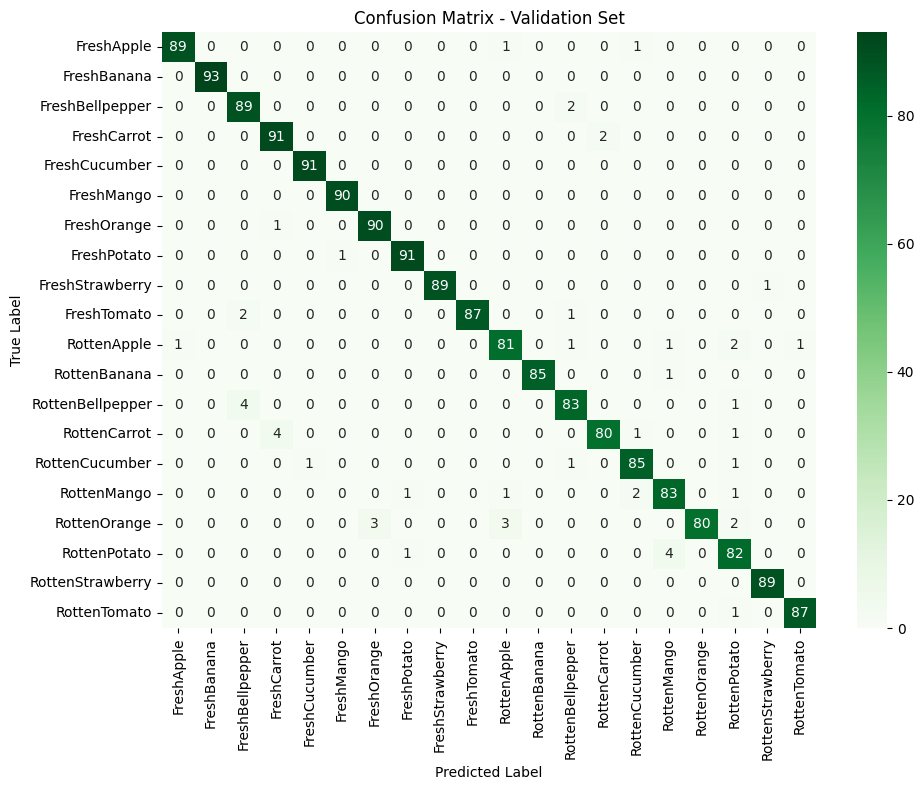

In [ ]:
# Execute evaluation function on validation set
evaluate("/content/drive/MyDrive/effnetb0_baseline_model.keras", val_gen, class_names)


Generating Grad-CAM explanations for model predictions...


/tmp/ipykernel_1727/1158656880.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet_heatmap = (cm.get_cmap("jet")(heatmap_resized)[:, :, :3] * 255).astype("uint8")


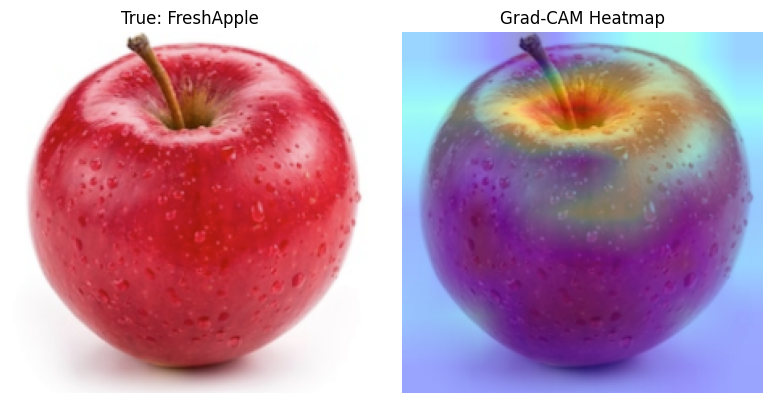

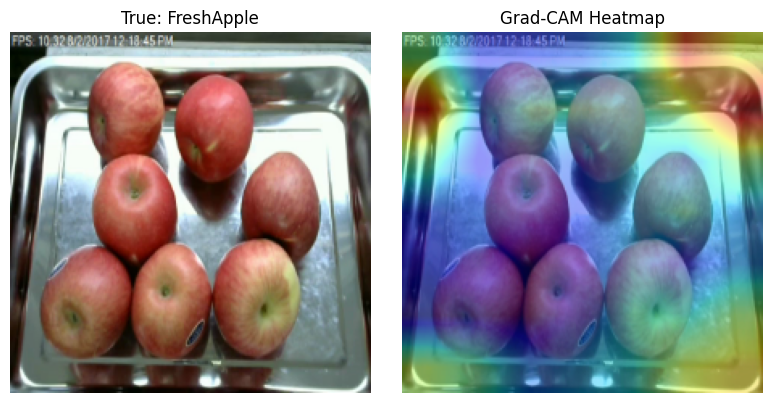

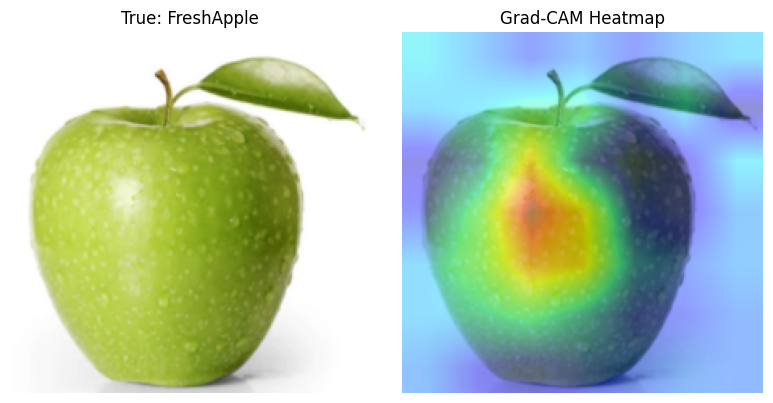

In [ ]:
# ==============================================================================
# 9. GRAD-CAM VISUALIZATION FUNCTION (OPTIMIZED FOR OVERWRITTEN GENERATORS)
# ==============================================================================
import matplotlib.cm as cm

def compute_gradcam_and_plot(model_path, dataset, class_names, num_samples=3):
    # Load model safely
    model = tf.keras.models.load_model(model_path)

    # Extract inner model feature extractor
    effnet_layer = model.layers[0]
    grad_model = tf.keras.models.Model([effnet_layer.input], [effnet_layer.output])

    # Get one batch of sample images from the validation set
    for images, labels in dataset.take(1):
        for idx in range(min(num_samples, len(images))):
            img_tensor = tf.expand_dims(images[idx], axis=0)
            true_idx = np.argmax(labels[idx])

            # Record gradients for the feature extraction part
            with tf.GradientTape() as tape:
                # Directly forward pass since dataset is preprocessed via .map()
                last_conv_layer_output = grad_model(img_tensor)

                # Forward pass through top layers via sequence index
                x = model.layers[1](last_conv_layer_output) # GlobalAveragePooling
                x = model.layers[2](x)                      # Dropout
                preds = model.layers[3](x)                  # Dense

                class_channel = preds[:, true_idx]

            # Compute gradients and weights
            grads = tape.gradient(class_channel, last_conv_layer_output)
            pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

            # Generate Heatmap
            heatmap = tf.squeeze(last_conv_layer_output[0] @ pooled_grads[..., tf.newaxis])
            heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)

            # Resize heatmap to target size (224, 224)
            heatmap_resized = tf.image.resize(heatmap[..., tf.newaxis], (224, 224)).numpy().squeeze()
            jet_heatmap = (cm.get_cmap("jet")(heatmap_resized)[:, :, :3] * 255).astype("uint8")

            # Re-scale preprocessed image tensors back to beautiful 0-255 RGB for display
            raw_img = images[idx].numpy()
            orig_img = ((raw_img - raw_img.min()) / (raw_img.max() - raw_img.min() + 1e-10) * 255).astype("uint8")

            # Blend Heatmap and Original image
            superimposed_img = tf.keras.preprocessing.image.array_to_img(jet_heatmap * 0.4 + orig_img * 0.6)

            # Plot side-by-side
            fig, axes = plt.subplots(1, 2, figsize=(8, 4))
            axes[0].imshow(orig_img)
            axes[0].set_title(f"True: {class_names[true_idx]}")
            axes[0].axis("off")

            axes[1].imshow(superimposed_img)
            axes[1].set_title("Grad-CAM Heatmap")
            axes[1].axis("off")
            plt.tight_layout()
            plt.show()

# Run Grad-CAM
print("\nGenerating Grad-CAM explanations for model predictions...")
compute_gradcam_and_plot("/content/drive/MyDrive/effnetb0_baseline_model.keras", val_gen, class_names)

# Improvement

# Experiment Set A: Classification Head & Training Callbacks
## Improvement 1: Improved Classification Head


The baseline model uses a single Dense layer with Dropout(0.2) as its classification head.
This improvement replaces it with a deeper and more regularized head to better capture
complex patterns in the freshness dataset.

| Component | Baseline | This Improvement |
|-----------|----------|-----------------|
| Dense Layers | 1 layer | 2 layers (256 → 128) |
| Dropout | 0.2 | 0.4 → 0.3 |
| Normalization | None | BatchNormalization |

 A deeper head allows the model to learn more abstract decision boundaries between
fresh and rotten classes, while BatchNormalization stabilizes training and higher dropout
reduces overfitting.

In [ ]:
# Load Baseline Model

# Load pretrained baseline model
baseline_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/effnetb0_baseline_model.keras"
)

# Baseline validation accuracy
history_val_accuracy = [
    0.9240, 0.9463, 0.9503, 0.9558,
    0.9547, 0.9581, 0.9603, 0.9609,
    0.9625, 0.9614
]

# Baseline validation loss
history_val_loss = [
    0.3354, 0.2300, 0.1849, 0.1670,
    0.1481, 0.1431, 0.1361, 0.1312,
    0.1275, 0.1288
]

In [ ]:
# Improved Classification Head


# Extract base model
base_model = baseline_model.layers[0]

# Freeze feature extractor
base_model.trainable = False

# Build improved classification head
improved_head_model = models.Sequential([

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(num_classes, activation='softmax')
])

# Show model summary
improved_head_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,418,103 (16.85 MB)

 Trainable params: 365,972 (1.40 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
# Compile Improved Head Model


# Compile model
improved_head_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# Train Improved Head Model

# Train model without callbacks
improved_head_history = improved_head_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 45s 127ms/step - accuracy: 0.7439 - loss: 0.8468 - val_accuracy: 0.9328 - val_loss: 0.2406
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 31s 117ms/step - accuracy: 0.8892 - loss: 0.3382 - val_accuracy: 0.9480 - val_loss: 0.1755
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 117ms/step - accuracy: 0.9170 - loss: 0.2568 - val_accuracy: 0.9647 - val_loss: 0.1293
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 119ms/step - accuracy: 0.9363 - loss: 0.1981 - val_accuracy: 0.9597 - val_loss: 0.1317
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 31s 118ms/step - accuracy: 0.9448 - loss: 0.1751 - val_accuracy: 0.9664 - val_loss: 0.1085
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 117ms/step - accuracy: 0.9499 - loss: 0.1627 - val_accuracy: 0.9636 - val_loss: 0.1240
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - accuracy: 0.9561 - loss: 0.1395 - val_accuracy: 0.9636 - val_loss: 0.1211
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - accuracy: 0.9587 - loss: 0

In [ ]:
#  Save Improved Head Model

# Save trained model
improved_head_model.save(
    "/content/drive/MyDrive/improved_head_model.keras"
)

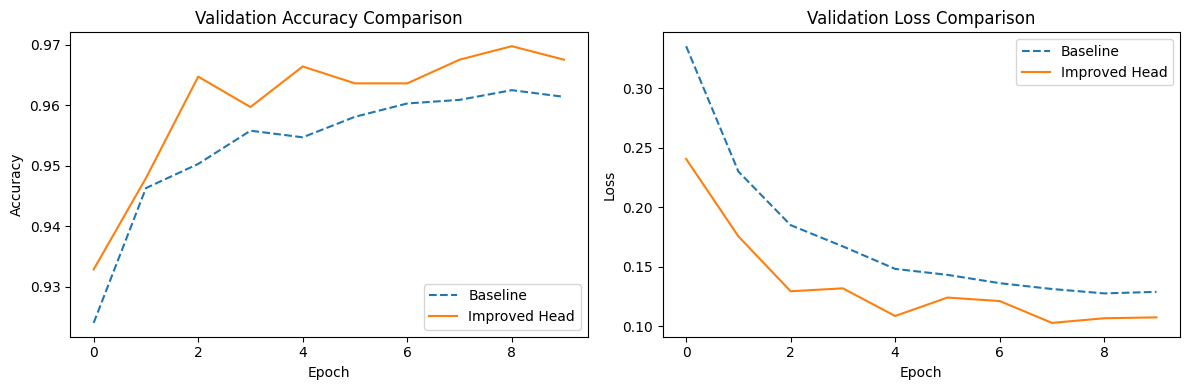

In [ ]:
#  Compare with Baseline

plt.figure(figsize=(12, 4))

# Accuracy comparison
plt.subplot(1, 2, 1)

plt.plot(
    history_val_accuracy,
    label='Baseline',
    linestyle='--'
)

plt.plot(
    improved_head_history.history['val_accuracy'],
    label='Improved Head'
)

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss comparison
plt.subplot(1, 2, 2)

plt.plot(
    history_val_loss,
    label='Baseline',
    linestyle='--'
)

plt.plot(
    improved_head_history.history['val_loss'],
    label='Improved Head'
)

plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Evaluating model and generating predictions...

Classification Report:
                  precision    recall  f1-score   support

      FreshApple     1.0000    0.9780    0.9889        91
     FreshBanana     1.0000    1.0000    1.0000        93
 FreshBellpepper     0.9263    0.9670    0.9462        91
     FreshCarrot     0.9474    0.9677    0.9574        93
   FreshCucumber     0.9681    1.0000    0.9838        91
      FreshMango     1.0000    0.9556    0.9773        90
     FreshOrange     0.9574    0.9890    0.9730        91
     FreshPotato     0.9684    1.0000    0.9840        92
 FreshStrawberry     1.0000    0.9889    0.9944        90
     FreshTomato     1.0000    0.9778    0.9888        90
     RottenApple     0.9130    0.9655    0.9385        87
    RottenBanana     0.9885    1.0000    0.9942        86
RottenBellpepper     0.9512    0.8864    0.9176        88
    RottenCarrot     0.9524    0.9302    0.9412        86
  RottenCucumber     0.9659    0.9659    0.9659        88


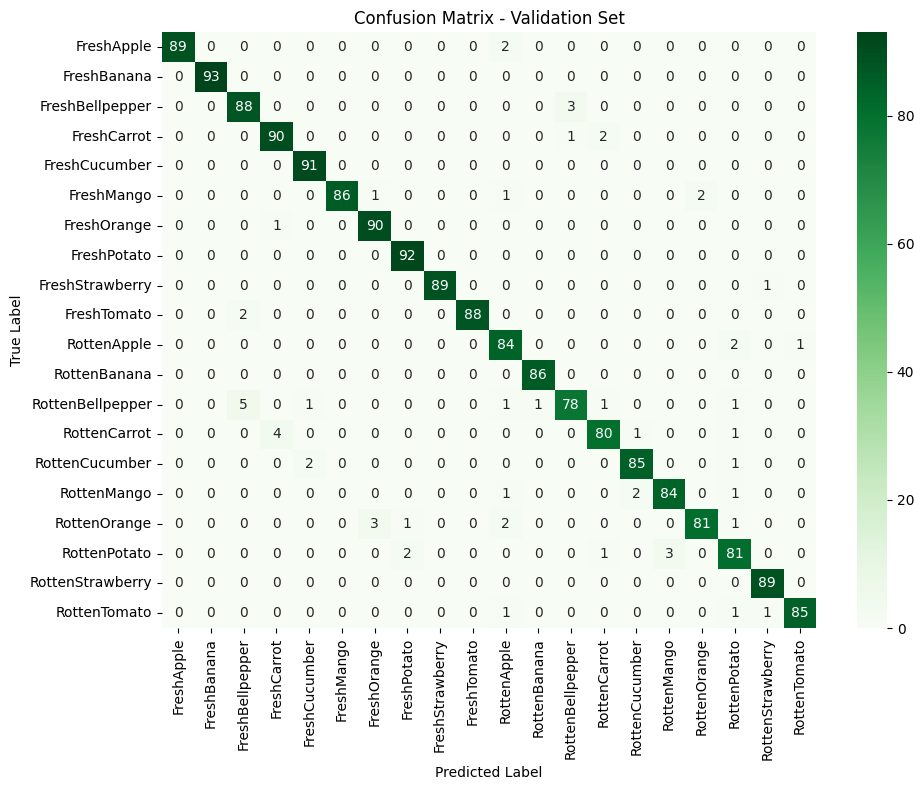

In [ ]:
# Evaluate Improved Head Model


# Evaluate model performance
evaluate(
    "/content/drive/MyDrive/improved_head_model.keras",
    val_gen,
    class_names
)

## Improvement 2: Training Callbacks


The baseline trains for a fixed 10 epochs with no adaptive control. This improvement adds
two callbacks that make training smarter and more efficient.

ReduceLROnPlateau — automatically halves the learning rate when validation loss
stops improving (patience=2, factor=0.5, min_lr=1e-7).

EarlyStopping — stops training when validation loss shows no improvement for 4 epochs
and restores the best weights automatically (patience=4, restore_best_weights=True).

| Setting | Baseline | This Improvement |
|---------|----------|-----------------|
| Learning Rate | Fixed 0.001 | Adaptive |
| Max Epochs | 10 | 10 (early stop) |
| Overfitting Control | Basic Dropout | EarlyStopping + ReduceLROnPlateau |

In [ ]:
#  Reload Baseline Model


# Reload baseline model
baseline_model2 = tf.keras.models.load_model(
    "/content/drive/MyDrive/effnetb0_baseline_model.keras"
)

# Extract feature extractor
base_model2 = baseline_model2.layers[0]

# Freeze base model
base_model2.trainable = False

In [ ]:
# Build Callbacks Model

# Build model with baseline head
callbacks_model = models.Sequential([

    base_model2,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.2),

    layers.Dense(num_classes, activation='softmax')
])

# Compile model
callbacks_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
#  Define Callbacks

# Reduce learning rate when validation loss stops improving
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# Stop training early to avoid overfitting
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
#  Train Callbacks Model

# Train model using callbacks
callbacks_history = callbacks_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=[lr_scheduler, early_stopping]
)

Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 48s 147ms/step - accuracy: 0.8162 - loss: 0.7711 - val_accuracy: 0.9267 - val_loss: 0.3139 - learning_rate: 0.0010
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 113ms/step - accuracy: 0.9355 - loss: 0.2590 - val_accuracy: 0.9457 - val_loss: 0.2110 - learning_rate: 0.0010
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 111ms/step - accuracy: 0.9535 - loss: 0.1832 - val_accuracy: 0.9569 - val_loss: 0.1706 - learning_rate: 0.0010
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 46s 129ms/step - accuracy: 0.9649 - loss: 0.1445 - val_accuracy: 0.9580 - val_loss: 0.1487 - learning_rate: 0.0010
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 113ms/step - accuracy: 0.9699 - loss: 0.1223 - val_accuracy: 0.9614 - val_loss: 0.1367 - learning_rate: 0.0010
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 31s 117ms/step - accuracy: 0.9770 - loss: 0.1010 - val_accuracy: 0.9619 - val_loss: 0.1261 - learning_rate: 0.0010
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 113ms/step - accuracy: 0.9

In [ ]:
#  Save Callbacks Model

# Save trained model
callbacks_model.save(
    "/content/drive/MyDrive/callbacks_model.keras"
)

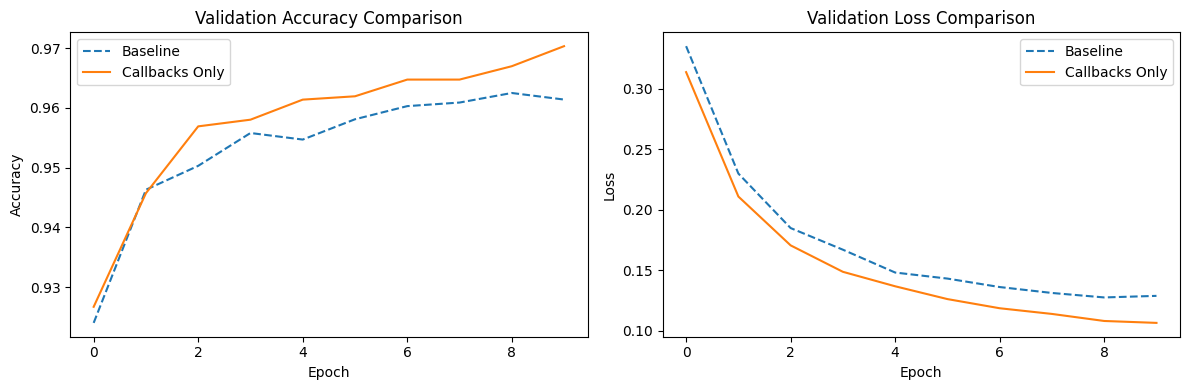

In [ ]:
#  Compare Callbacks Model with Baseline


plt.figure(figsize=(12, 4))

# Accuracy comparison
plt.subplot(1, 2, 1)

plt.plot(
    history_val_accuracy,
    label='Baseline',
    linestyle='--'
)

plt.plot(
    callbacks_history.history['val_accuracy'],
    label='Callbacks Only'
)

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss comparison
plt.subplot(1, 2, 2)

plt.plot(
    history_val_loss,
    label='Baseline',
    linestyle='--'
)

plt.plot(
    callbacks_history.history['val_loss'],
    label='Callbacks Only'
)

plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Evaluating model and generating predictions...

Classification Report:
                  precision    recall  f1-score   support

      FreshApple     0.9890    0.9890    0.9890        91
     FreshBanana     1.0000    1.0000    1.0000        93
 FreshBellpepper     0.9368    0.9780    0.9570        91
     FreshCarrot     0.9286    0.9785    0.9529        93
   FreshCucumber     0.9681    1.0000    0.9838        91
      FreshMango     0.9890    1.0000    0.9945        90
     FreshOrange     0.9890    0.9890    0.9890        91
     FreshPotato     0.9681    0.9891    0.9785        92
 FreshStrawberry     1.0000    1.0000    1.0000        90
     FreshTomato     1.0000    0.9667    0.9831        90
     RottenApple     0.9643    0.9310    0.9474        87
    RottenBanana     1.0000    1.0000    1.0000        86
RottenBellpepper     0.9432    0.9432    0.9432        88
    RottenCarrot     0.9750    0.9070    0.9398        86
  RottenCucumber     0.9326    0.9432    0.9379        88


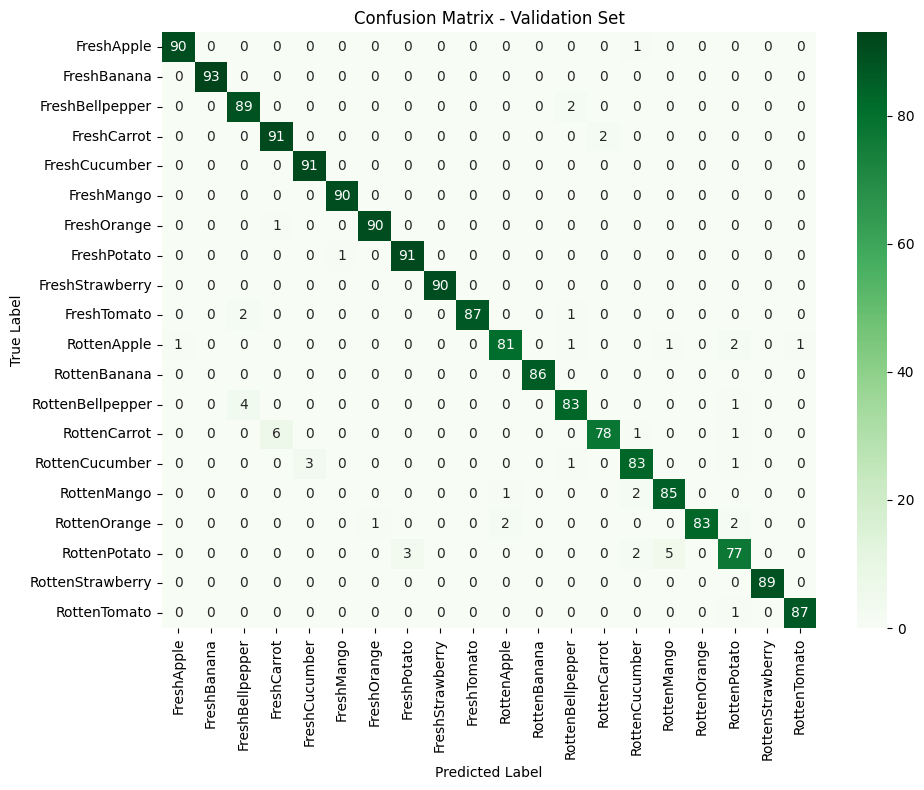

In [ ]:
# Evaluate callbacks model
evaluate(
   "/content/drive/MyDrive/callbacks_model.keras",
   val_gen,
   class_names
)

---
# Experiment Set B: Fine-Tuning, L2 Regularization & Label Smoothing


This section contains three independent model improvements, each tested separately on the validation set.
The baseline model uses EfficientNetB0 with all layers frozen, Adam (lr=0.001), 0.2 Dropout, and standard Categorical Crossentropy.


## Additional Imports & Helper Utilities

In [ ]:
# Additional imports needed for evaluation
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

# find the EfficientNetB0 sub-layer inside a Sequential model
def find_efficientnet_layer(sequential_model):
    """Return the EfficientNetB0 Functional sub-layer, however the model is structured."""
    for layer in sequential_model.layers:
        if 'efficientnetb0' in layer.name.lower():
            return layer
    raise ValueError("EfficientNetB0 layer not found in model. Layers: " +
                     str([l.name for l in sequential_model.layers]))

# evaluate any trained model on val_gen
def evaluate_on_val(trained_model, val_generator, model_name="Model"):
    """
    Runs prediction on the full validation set and prints:
      - Validation accuracy, precision, recall, F1-score
      - Full classification report
      - Confusion matrix heatmap
    """
    val_generator.reset()
    y_pred_probs = trained_model.predict(val_generator, verbose=1)
    y_pred       = np.argmax(y_pred_probs, axis=1)
    y_true       = val_generator.classes

    class_labels = list(val_generator.class_indices.keys())

    acc  = np.mean(y_pred == y_true)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    print(f"\n{'='*55}")
    print(f"  {model_name} — Validation Results")
    print(f"{'='*55}")
    print(f"  Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
    print(f"  Precision : {prec:.4f}")
    print(f"  Recall    : {rec:.4f}")
    print(f"  F1-Score  : {f1:.4f}")
    print(f"{'='*55}\n")

    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_labels, zero_division=0))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(14, 12))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f"Confusion Matrix — {model_name}", fontsize=14)
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}


---
## Improvement 1: Fine-Tuning EfficientNetB0

**What it is:**  
In this improvement, the last layers of EfficientNetB0 are unfrozen while the earlier layers remain frozen.
The goal is to allow the model to learn more task-specific visual features from the freshness dataset
while still using the pretrained ImageNet knowledge.

**Why it is used:**  
Transfer learning with a fully frozen backbone extracts generic features.
Unfreezing the last few layers allows the network to adapt those high-level features specifically
to fruit/vegetable freshness patterns — at low risk of destroying the useful lower-level features.

**What it changes:**  
Only the last 20 layers of the EfficientNetB0 backbone become trainable.
The classification head is identical to the baseline (GlobalAveragePooling → Dropout(0.2) → Dense(num_classes)).
A very small learning rate (1e-5) is used to avoid overwriting pretrained weights.



In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the baseline model creation function (copied from BS0Z8762t7F8)
def create_effnetb0_baseline(num_classes, input_shape=(224, 224, 3)):
    # Load pretrained EfficientNetB0
    # include_top=False removes the original classifier head
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )

    # Freeze the base model to prevent training
    base_model.trainable = False

    # Build classification head
    model = models.Sequential([
        base_model,                         # feature extractor
        layers.GlobalAveragePooling2D(),    # convert features to vector
        layers.Dropout(0.2),                # reduce overfitting
        layers.Dense(num_classes, activation="softmax")  # output layer
    ])

    return model

# find the EfficientNetB0 sub-layer inside a Sequential model (copied from 6CPb1q3nmThH)
def find_efficientnet_layer(sequential_model):
    """Return the EfficientNetB0 Functional sub-layer, however the model is structured."""
    for layer in sequential_model.layers:
        if 'efficientnetb0' in layer.name.lower():
            return layer
    raise ValueError("EfficientNetB0 layer not found in model. Layers: " +
                     str([l.name for l in sequential_model.layers]))

# Define num_classes here to make the cell self-contained for this variable
# class_names is expected to be available from previous cells (e.g., omcvU41tjL1M)
num_classes = len(class_names)

# Improvement 1: Fine-Tuning EfficientNetB0

# 1. Build a fresh baseline model
ft_model = create_effnetb0_baseline(num_classes)

# 2. Locate the EfficientNetB0 sub-layer safely
effnet_layer = find_efficientnet_layer(ft_model)
print("Found EfficientNet layer:", effnet_layer.name)
print("Total layers in EfficientNetB0:", len(effnet_layer.layers))

# 3. Unfreeze only the last 20 layers of EfficientNetB0
effnet_layer.trainable = True                        # enable editing sub-layers
UNFREEZE_LAST_N = 20
for layer in effnet_layer.layers[:-UNFREEZE_LAST_N]:
    layer.trainable = False                          # keep early layers frozen
for layer in effnet_layer.layers[-UNFREEZE_LAST_N:]:
    layer.trainable = True                           # allow last N layers to train

# Count trainable vs frozen
trainable_count    = sum(1 for l in ft_model.trainable_weights)
non_trainable_count = sum(1 for l in ft_model.non_trainable_weights)
print(f"Trainable weight tensors   : {trainable_count}")
print(f"Non-trainable weight tensors: {non_trainable_count}")

# 4. Compile with a very small learning rate to preserve pretrained features
ft_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

ft_model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Found EfficientNet layer: efficientnetb0
Total layers in EfficientNetB0: 238
Trainable weight tensors   : 21
Non-trainable weight tensors: 293


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 1,376,580 (5.25 MB)

 Non-trainable params: 2,698,611 (10.29 MB)

In [ ]:
# Train Improvement 1 (Fine-Tuning)

ft_history = ft_model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    verbose=1
)


Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 57s 147ms/step - accuracy: 0.1979 - loss: 2.7640 - val_accuracy: 0.4466 - val_loss: 2.3289
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 37s 140ms/step - accuracy: 0.5158 - loss: 2.1408 - val_accuracy: 0.6715 - val_loss: 1.7098
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 36s 123ms/step - accuracy: 0.6902 - loss: 1.6287 - val_accuracy: 0.7902 - val_loss: 1.2596
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 37s 139ms/step - accuracy: 0.7735 - loss: 1.2603 - val_accuracy: 0.8394 - val_loss: 0.9565
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 32s 124ms/step - accuracy: 0.8207 - loss: 0.9905 - val_accuracy: 0.8651 - val_loss: 0.7525
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 32s 122ms/step - accuracy: 0.8532 - loss: 0.7996 - val_accuracy: 0.8842 - val_loss: 0.6112
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 33s 125ms/step - accuracy: 0.8684 - loss: 0.6700 - val_accuracy: 0.8982 - val_loss: 0.5129
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 36s 138ms/step - accuracy: 0.8891 - loss: 0


  Improvement 1: Fine-Tuning EfficientNetB0 — Validation Results
  Accuracy  : 0.9211  (92.11%)
  Precision : 0.9227
  Recall    : 0.9211
  F1-Score  : 0.9213

Classification Report:
                  precision    recall  f1-score   support

      FreshApple       0.93      0.91      0.92        91
     FreshBanana       1.00      1.00      1.00        93
 FreshBellpepper       0.89      0.95      0.91        91
     FreshCarrot       0.94      0.88      0.91        93
   FreshCucumber       0.93      0.93      0.93        91
      FreshMango       0.93      0.93      0.93        90
     FreshOrange       0.94      0.92      0.93        91
     FreshPotato       0.85      0.95      0.90        92
 FreshStrawberry       0.99      1.00      0.99        90
     FreshTomato       0.98      0.91      0.94        90
     RottenApple       0.85      0.85      0.85        87
    RottenBanana       1.00      1.00      1.00        86
RottenBellpepper       0.83      0.86      0.84        88
   

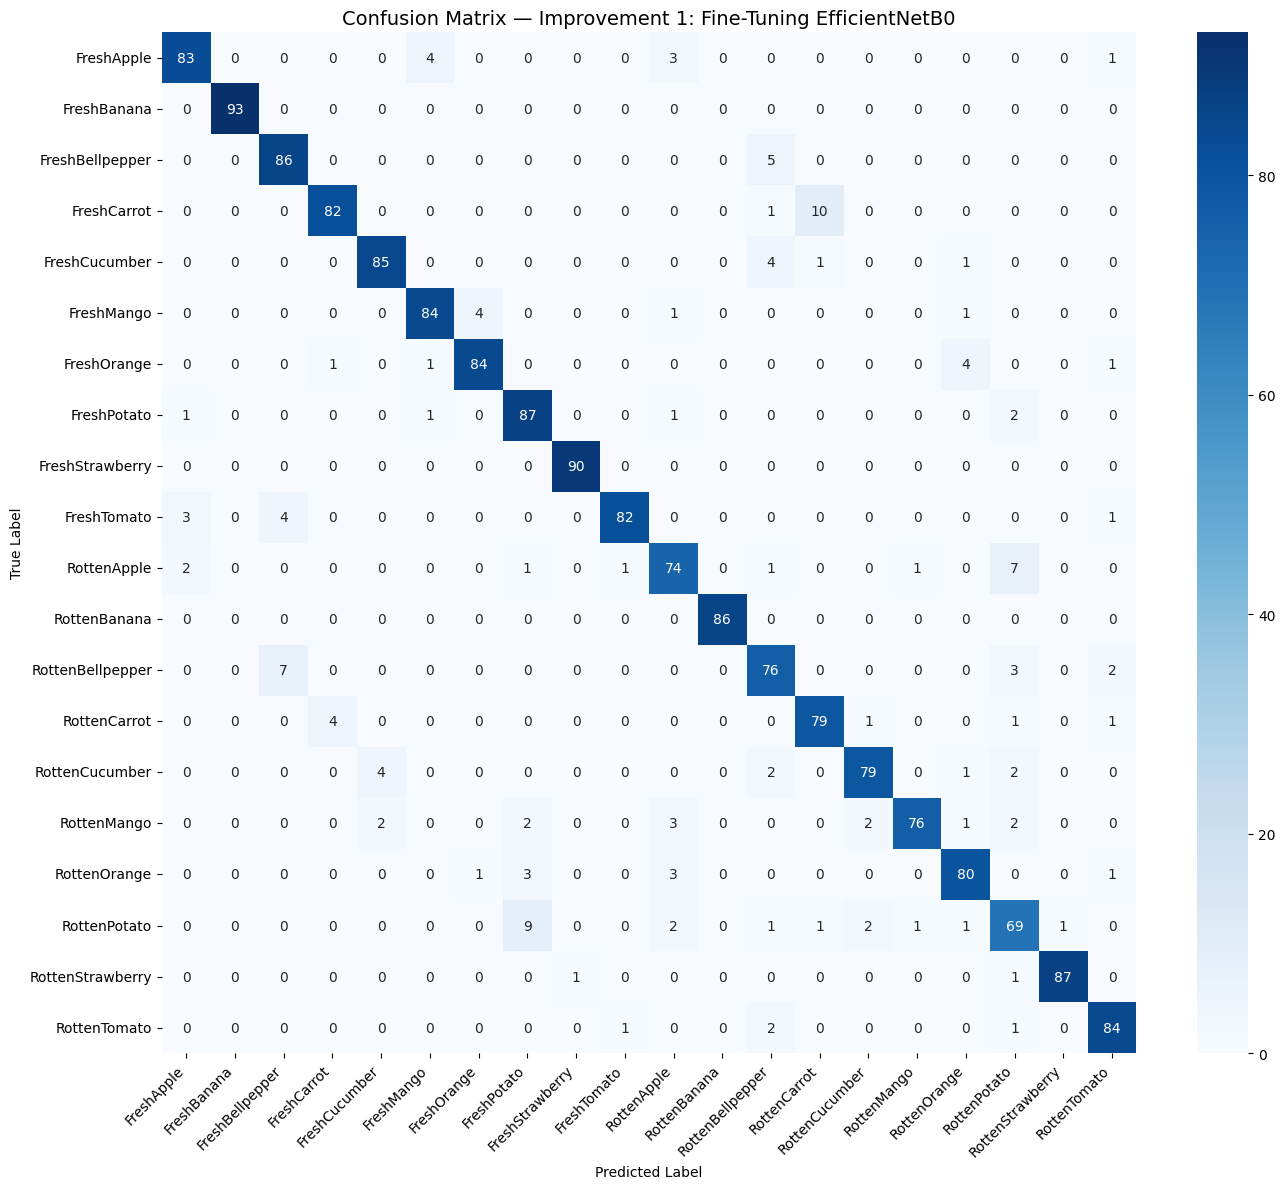

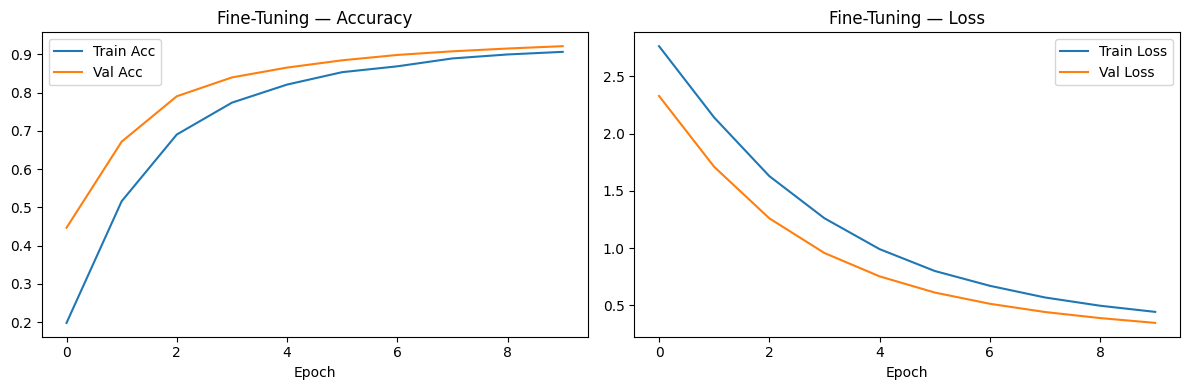

In [ ]:
# Evaluate Improvement 1 on Validation Set

# Extract true labels and make predictions
y_true = []
y_pred = []

# val_gen is a tf.data.Dataset, so iterate over it
for images, labels in val_gen:
    preds = ft_model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate metrics
acc = np.mean(y_pred == y_true)
prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

# Print results
model_name = "Improvement 1: Fine-Tuning EfficientNetB0"
print(f"\n{'='*55}")
print(f"  {model_name} — Validation Results")
print(f"{'='*55}")
print(f"  Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print(f"{'='*55}\n")

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix — {model_name}", fontsize=14)
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Store results
results_ft = {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# Plot training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ft_history.history['accuracy'],     label='Train Acc')
plt.plot(ft_history.history['val_accuracy'], label='Val Acc')
plt.title('Fine-Tuning — Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ft_history.history['loss'],     label='Train Loss')
plt.plot(ft_history.history['val_loss'], label='Val Loss')
plt.title('Fine-Tuning — Loss'); plt.xlabel('Epoch'); plt.legend()

plt.tight_layout()
plt.show()

---
## Improvement 2: L2 Regularization

**What it is:**  
In this improvement, L2 regularization is added to the Dense layer to reduce overfitting.
It discourages very large weights and helps the model generalize better on unseen validation data.

**Why it is used:**  
L2 regularization penalizes large weight values during training by adding a term proportional
to the sum of squared weights to the loss. This forces the model to distribute weight values
more evenly and avoid relying too heavily on any single feature, improving generalization.

**What it changes:**  
Only the Dense output layer's kernel regularizer is changed — from none to `l2(0.001)`.
The architecture is otherwise identical to the baseline (fully frozen EfficientNetB0,
GlobalAveragePooling, Dropout(0.2)). No BatchNorm or extra Dense layers are added
(those are already used in another student's improvement).




In [ ]:
# Improvement 2: L2 Regularization

def create_model_l2(num_classes, input_shape=(224, 224, 3), l2_lambda=0.001):
    """Baseline architecture with L2 regularization on the Dense output layer."""
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )
    base_model.trainable = False  # Keep fully frozen (same as baseline)

    model = tf.keras.models.Sequential([
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(
            num_classes,
            activation="softmax",
            kernel_regularizer=tf.keras.regularizers.l2(l2_lambda)  # ← only change
        )
    ])
    return model

l2_model = create_model_l2(num_classes, l2_lambda=0.001)

l2_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

l2_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# Train Improvement 2 (L2 Regularization)

l2_history = l2_model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    verbose=1
)


Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 43s 124ms/step - accuracy: 0.8066 - loss: 0.8518 - val_accuracy: 0.9267 - val_loss: 0.3970
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 115ms/step - accuracy: 0.9343 - loss: 0.3486 - val_accuracy: 0.9474 - val_loss: 0.3103
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 115ms/step - accuracy: 0.9535 - loss: 0.2877 - val_accuracy: 0.9524 - val_loss: 0.2820
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 115ms/step - accuracy: 0.9616 - loss: 0.2612 - val_accuracy: 0.9564 - val_loss: 0.2662
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 114ms/step - accuracy: 0.9679 - loss: 0.2432 - val_accuracy: 0.9569 - val_loss: 0.2567
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 115ms/step - accuracy: 0.9703 - loss: 0.2346 - val_accuracy: 0.9603 - val_loss: 0.2510
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 113ms/step - accuracy: 0.9741 - loss: 0.2255 - val_accuracy: 0.9647 - val_loss: 0.2471
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 42s 115ms/step - accuracy: 0.9747 - loss: 0


  Improvement 2: L2 Regularization — Validation Results
  Accuracy  : 0.9642  (96.42%)
  Precision : 0.9651
  Recall    : 0.9642
  F1-Score  : 0.9643

Classification Report:
                  precision    recall  f1-score   support

      FreshApple       0.99      0.97      0.98        91
     FreshBanana       1.00      1.00      1.00        93
 FreshBellpepper       0.92      0.98      0.95        91
     FreshCarrot       0.93      0.98      0.95        93
   FreshCucumber       0.97      1.00      0.98        91
      FreshMango       0.99      0.98      0.98        90
     FreshOrange       0.96      0.99      0.97        91
     FreshPotato       0.97      0.98      0.97        92
 FreshStrawberry       1.00      0.99      0.99        90
     FreshTomato       1.00      0.98      0.99        90
     RottenApple       0.93      0.92      0.92        87
    RottenBanana       1.00      0.99      0.99        86
RottenBellpepper       0.96      0.91      0.94        88
    RottenCa

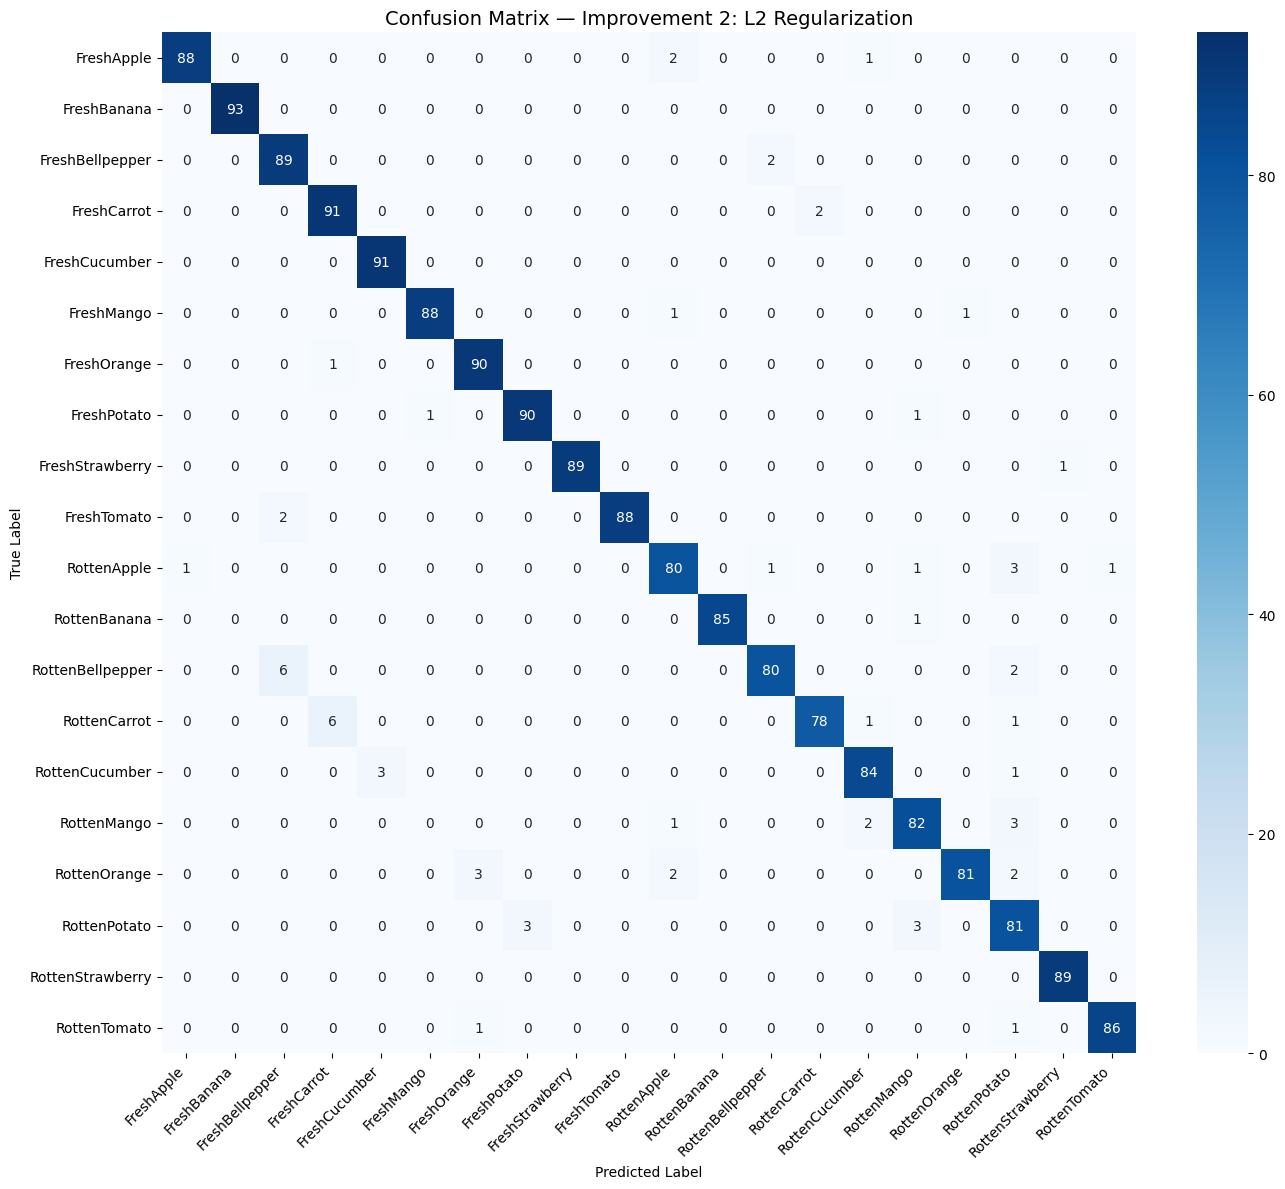

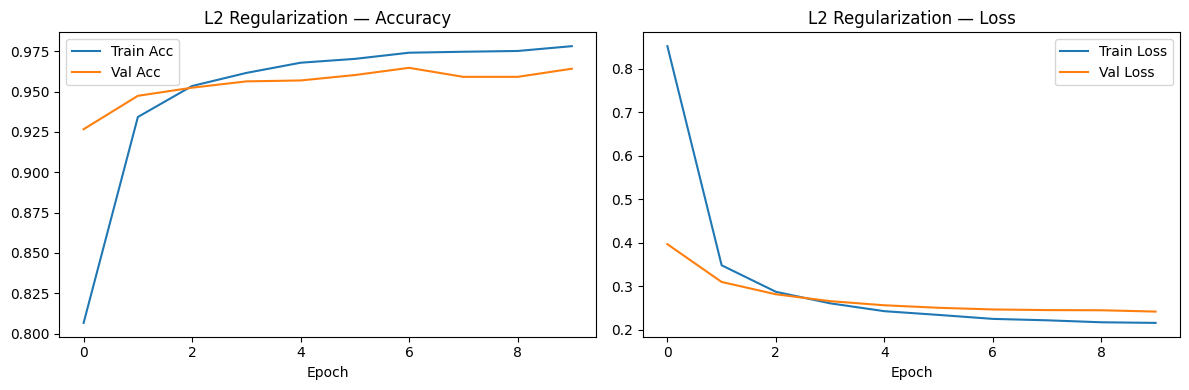

In [ ]:
# Evaluate Improvement 2 on Validation Set

# 1. Get predictions and true labels from val_gen
y_true_list = []
y_pred_list = []

# val_gen is a tf.data.Dataset, so iterate over it
for images, labels in val_gen:
    preds = l2_model.predict(images, verbose=0)
    y_pred_list.extend(np.argmax(preds, axis=1))
    y_true_list.extend(np.argmax(labels.numpy(), axis=1)) # Convert one-hot labels to class indices

y_true = np.array(y_true_list)
y_pred = np.array(y_pred_list)

# 2. Calculate metrics (using class_names defined in omcvU41tjL1M)
acc  = np.mean(y_pred == y_true)
prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)

results_l2 = {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# 3. Print results
model_name = "Improvement 2: L2 Regularization"
print(f"\n{'='*55}")
print(f"  {model_name} — Validation Results")
print(f"{'='*55}")
print(f"  Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print(f"{'='*55}\n")

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix — {model_name}", fontsize=14)
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plot training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(l2_history.history['accuracy'],     label='Train Acc')
plt.plot(l2_history.history['val_accuracy'], label='Val Acc')
plt.title('L2 Regularization — Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(l2_history.history['loss'],     label='Train Loss')
plt.plot(l2_history.history['val_loss'], label='Val Loss')
plt.title('L2 Regularization — Loss'); plt.xlabel('Epoch'); plt.legend()

plt.tight_layout()
plt.show()


---
## Improvement 3: Label Smoothing

**What it is:**  
In this improvement, label smoothing is applied to the categorical crossentropy loss.
The goal is to reduce overconfidence in predictions and improve generalization,
especially when some freshness classes look visually similar.

**Why it is used:**  
Standard one-hot labels push the model to predict probabilities of exactly 0 or 1,
which can lead to overconfident and poorly calibrated predictions.
Label smoothing replaces hard 0/1 targets with soft values (e.g. 0.005 / 0.995 for 20 classes),
which acts as a regularizer and often improves performance on visually similar classes.

**What it changes:**  
Only the loss function changes — from standard `CategoricalCrossentropy` to
`CategoricalCrossentropy(label_smoothing=0.1)`.
The model architecture and all other settings remain identical to the baseline.



In [ ]:
# Improvement 3: Label Smoothing

# Build fresh baseline model (fully frozen EfficientNetB0 + same head)
ls_model = create_effnetb0_baseline(num_classes)

# Compile with label-smoothed loss — the only change from the baseline
ls_loss = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)

ls_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=ls_loss,           # ← label smoothing applied here
    metrics=["accuracy"]
)

ls_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
#Train Improvement 3 (Label Smoothing)

ls_history = ls_model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    verbose=1
)


Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 42s 123ms/step - accuracy: 0.8155 - loss: 1.2208 - val_accuracy: 0.9245 - val_loss: 0.8875
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 38s 110ms/step - accuracy: 0.9402 - loss: 0.8620 - val_accuracy: 0.9452 - val_loss: 0.8213
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 32s 122ms/step - accuracy: 0.9571 - loss: 0.8089 - val_accuracy: 0.9502 - val_loss: 0.7946
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 112ms/step - accuracy: 0.9645 - loss: 0.7802 - val_accuracy: 0.9586 - val_loss: 0.7768
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 113ms/step - accuracy: 0.9704 - loss: 0.7645 - val_accuracy: 0.9586 - val_loss: 0.7678
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 114ms/step - accuracy: 0.9788 - loss: 0.7506 - val_accuracy: 0.9603 - val_loss: 0.7585
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - accuracy: 0.9790 - loss: 0.7420 - val_accuracy: 0.9642 - val_loss: 0.7528
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 112ms/step - accuracy: 0.9797 - loss: 0


  Improvement 3: Label Smoothing — Validation Results
  Accuracy  : 0.9653  (96.53%)
  Precision : 0.9660
  Recall    : 0.9653
  F1-Score  : 0.9652

Classification Report:
                  precision    recall  f1-score   support

      FreshApple       0.99      0.99      0.99        91
     FreshBanana       1.00      1.00      1.00        93
 FreshBellpepper       0.90      0.97      0.93        91
     FreshCarrot       0.93      0.98      0.95        93
   FreshCucumber       0.97      1.00      0.98        91
      FreshMango       1.00      0.98      0.99        90
     FreshOrange       0.98      0.99      0.98        91
     FreshPotato       0.94      1.00      0.97        92
 FreshStrawberry       1.00      0.99      0.99        90
     FreshTomato       1.00      0.96      0.98        90
     RottenApple       0.93      0.94      0.94        87
    RottenBanana       0.99      1.00      0.99        86
RottenBellpepper       0.92      0.88      0.90        88
    RottenCarr

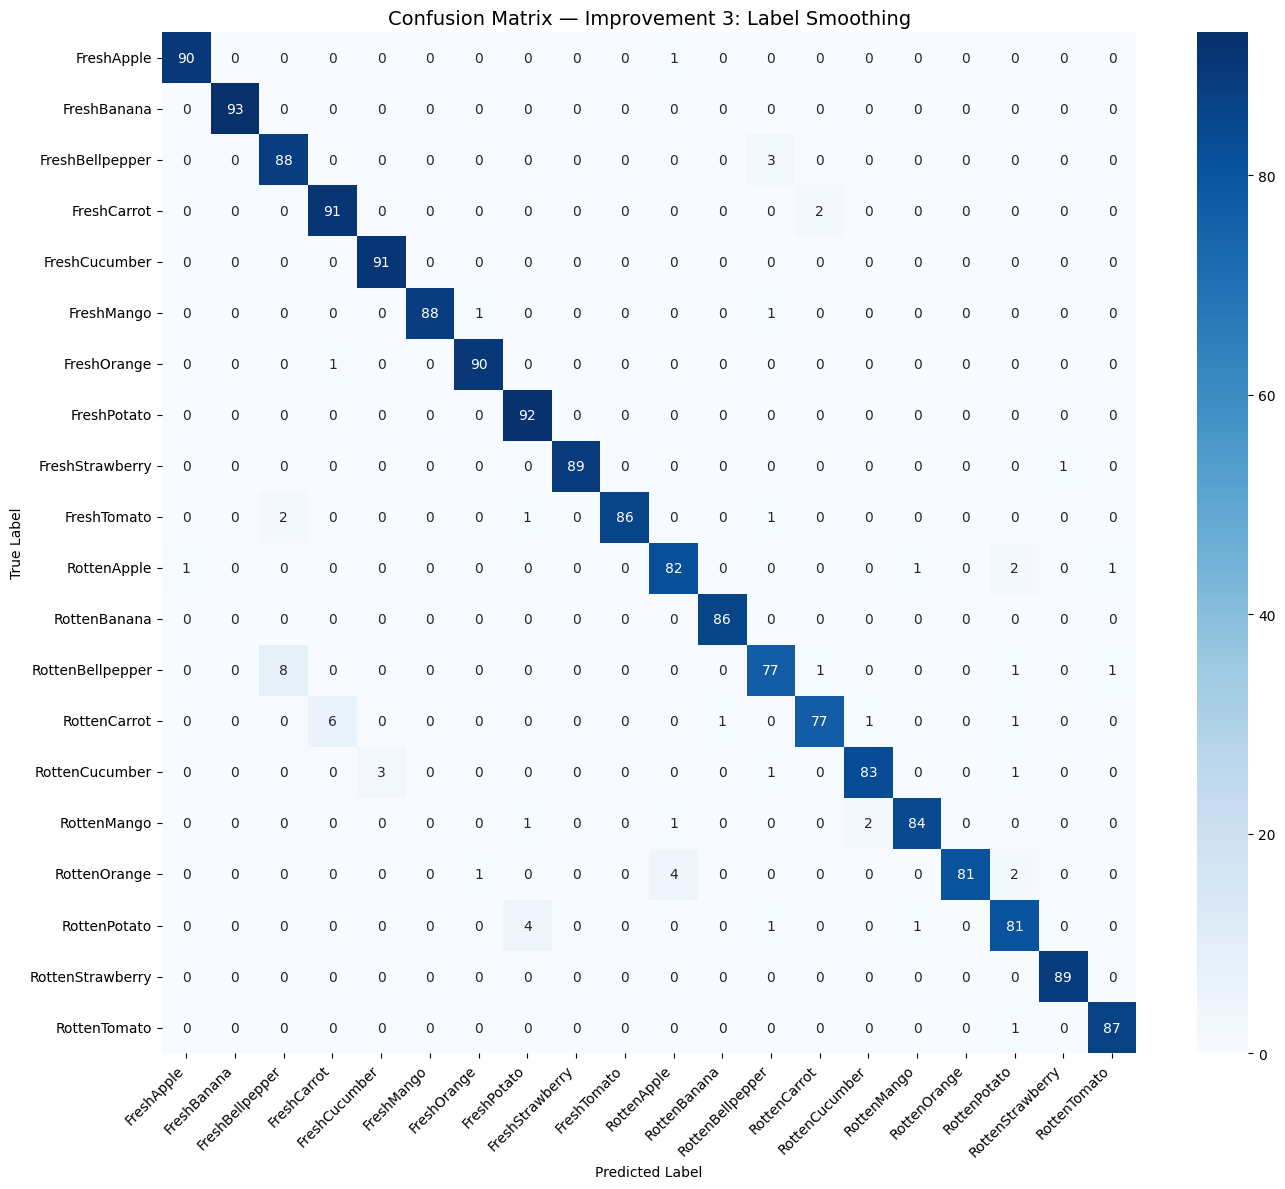

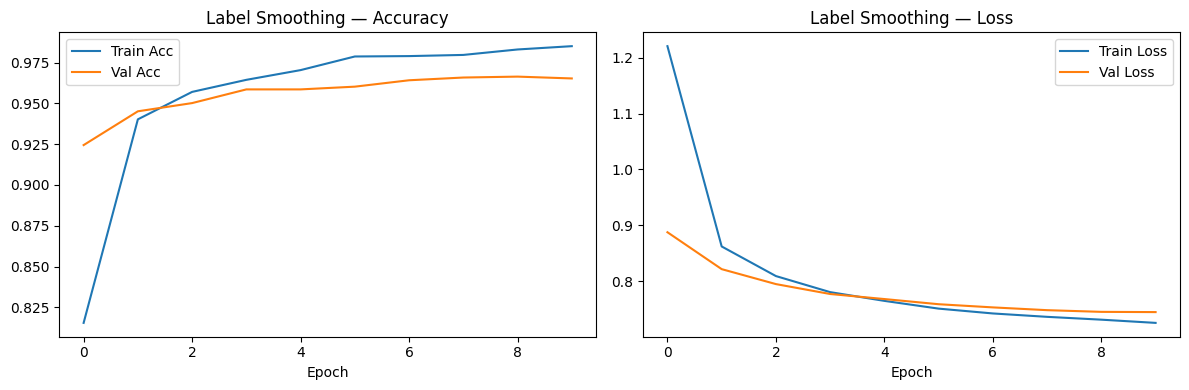

In [ ]:
# Evaluate Improvement 3 on Validation Set

# 1. Get predictions and true labels from val_gen
y_true_list = []
y_pred_list = []

# val_gen is a tf.data.Dataset, so iterate over it
for images, labels in val_gen:
    preds = ls_model.predict(images, verbose=0)
    y_pred_list.extend(np.argmax(preds, axis=1))
    y_true_list.extend(np.argmax(labels.numpy(), axis=1)) # Convert one-hot labels to class indices

y_true = np.array(y_true_list)
y_pred = np.array(y_pred_list)

# 2. Calculate metrics (using class_names defined in omcvU41tjL1M)
acc  = np.mean(y_pred == y_true)
prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)

results_ls = {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# 3. Print results
model_name = "Improvement 3: Label Smoothing"
print(f"\n{'='*55}")
print(f"  {model_name} — Validation Results")
print(f"{'='*55}")
print(f"  Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print(f"{'='*55}\n")

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix — {model_name}", fontsize=14)
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plot training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ls_history.history['accuracy'],     label='Train Acc')
plt.plot(ls_history.history['val_accuracy'], label='Val Acc')
plt.title('Label Smoothing — Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ls_history.history['loss'],     label='Train Loss')
plt.plot(ls_history.history['val_loss'], label='Val Loss')
plt.title('Label Smoothing — Loss'); plt.xlabel('Epoch'); plt.legend()

plt.tight_layout()
plt.show()

 # Experiment Set C: Augmentation, Cosine LR Schedule & MixUp
This section contains three independent model improvements,
 each tested separately on the validation set.
#Implemented Improvements:
 1. Advanced Data Augmentation
 2. Cosine Learning Rate Schedule
 3. MixUp Augmentation

All improvements are compared directly with the baseline model under the same training and evaluation conditions.


In [ ]:
def evaluate_on_val(model, generator, model_name="Model"):
    # Reset generator
    generator.reset()

    # True labels
    y_true = generator.classes

    # Predictions
    y_pred = np.argmax(
        model.predict(generator, steps=len(generator)),
        axis=1
    )

    # Class names
    class_names = list(generator.class_indices.keys())

    # Classification report
    print(f"\n{'='*60}")
    print(model_name)
    print('='*60)
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion Matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        confusion_matrix(y_true, y_pred),
        annot=True,
        fmt='d',
        cmap='Greens',
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    # Accuracy
    accuracy = np.mean(y_true == y_pred)
    print(f"Validation Accuracy: {accuracy:.4f}")

    return {
        "model_name": model_name,
        "val_accuracy": accuracy
    }

 ## Improvement 1: Advanced Data Augmentation

**What it is:**

In this improvement, a complete augmentation pipeline is applied to the training data for the first time, including `brightness_range` and `shear_range`.
This forces the model to be invariant to lighting changes and perspective distortions.

**Why it is used:**

The baseline had no augmentation — it trained on raw images as-is.
Fruit and vegetable freshness images can vary significantly in brightness (different lighting conditions)
and in perspective (camera angle). Adding a full augmentation pipeline exposes the model
to a wider variety of realistic input conditions, reducing overfitting and improving generalization.

**What it changes:**

A new `ImageDataGenerator` is created with all augmentation parameters — rotation, zoom, shift, flip, brightness, and shear.
The model architecture, optimizer, and all other settings remain identical to the baseline.

| Augmentation | Baseline | This Improvement |
|---|---|---|
| Rotation | — | 20° |
| Zoom | — | 0.2 |
| Shift (W/H) | — | 0.1 |
| Horizontal Flip | — | Yes |
| Brightness range | — | [0.7, 1.3] |
| Shear range | — | 0.15 |

In [ ]:
# Improvement Advanced Data Augmentation

# Build a fresh baseline model (same architecture as baseline)
aug_model = create_effnetb0_baseline(num_classes)

# Compile with same settings as baseline
aug_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

aug_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# Create a  augmentation generator for training only
aug_train_datagen = ImageDataGenerator(
    preprocessing_function=effnet_preprocess,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.7, 1.3],
    shear_range=0.15
)

# Load training data with the stronger augmentation
aug_train_gen = aug_train_datagen.flow_from_directory(
    '/content/data/splitted_data/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

# Validation uses the same generator as baseline
print(f"Augmented train samples: {aug_train_gen.samples}")


Found 8383 images belonging to 20 classes.
Augmented train samples: 8383


In [ ]:
# Train Improvement 1

aug_history = aug_model.fit(
    aug_train_gen,           # stronger augmented training data
    epochs=10,
    validation_data=val_gen, # same validation set as baseline
    verbose=1
)

Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 187s 632ms/step - accuracy: 0.7939 - loss: 0.8572 - val_accuracy: 0.9240 - val_loss: 0.3408
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 142s 542ms/step - accuracy: 0.9188 - loss: 0.3110 - val_accuracy: 0.9346 - val_loss: 0.2448
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 143s 546ms/step - accuracy: 0.9356 - loss: 0.2408 - val_accuracy: 0.9458 - val_loss: 0.1955
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 145s 555ms/step - accuracy: 0.9443 - loss: 0.1955 - val_accuracy: 0.9497 - val_loss: 0.1832
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 143s 545ms/step - accuracy: 0.9538 - loss: 0.1686 - val_accuracy: 0.9564 - val_loss: 0.1655
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 140s 535ms/step - accuracy: 0.9606 - loss: 0.1491 - val_accuracy: 0.9542 - val_loss: 0.1581
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 142s 542ms/step - accuracy: 0.9614 - loss: 0.1340 - val_accuracy: 0.9547 - val_loss: 0.1570
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 141s 538ms/step - accuracy: 0.9640 -

56/56 ━━━━━━━━━━━━━━━━━━━━ 20s 251ms/step

Improvement 1: Advanced Data Augmentation
                  precision    recall  f1-score   support

      FreshApple       0.96      1.00      0.98        91
     FreshBanana       1.00      1.00      1.00        93
 FreshBellpepper       0.95      0.97      0.96        91
     FreshCarrot       0.93      0.98      0.95        93
   FreshCucumber       0.95      1.00      0.97        91
      FreshMango       0.95      0.99      0.97        90
     FreshOrange       0.98      0.97      0.97        91
     FreshPotato       0.97      0.91      0.94        92
 FreshStrawberry       1.00      1.00      1.00        90
     FreshTomato       0.99      0.99      0.99        90
     RottenApple       0.92      0.90      0.91        88
    RottenBanana       1.00      1.00      1.00        86
RottenBellpepper       0.95      0.83      0.88        88
    RottenCarrot       0.93      0.89      0.91        87
  RottenCucumber       0.98      0.97      0

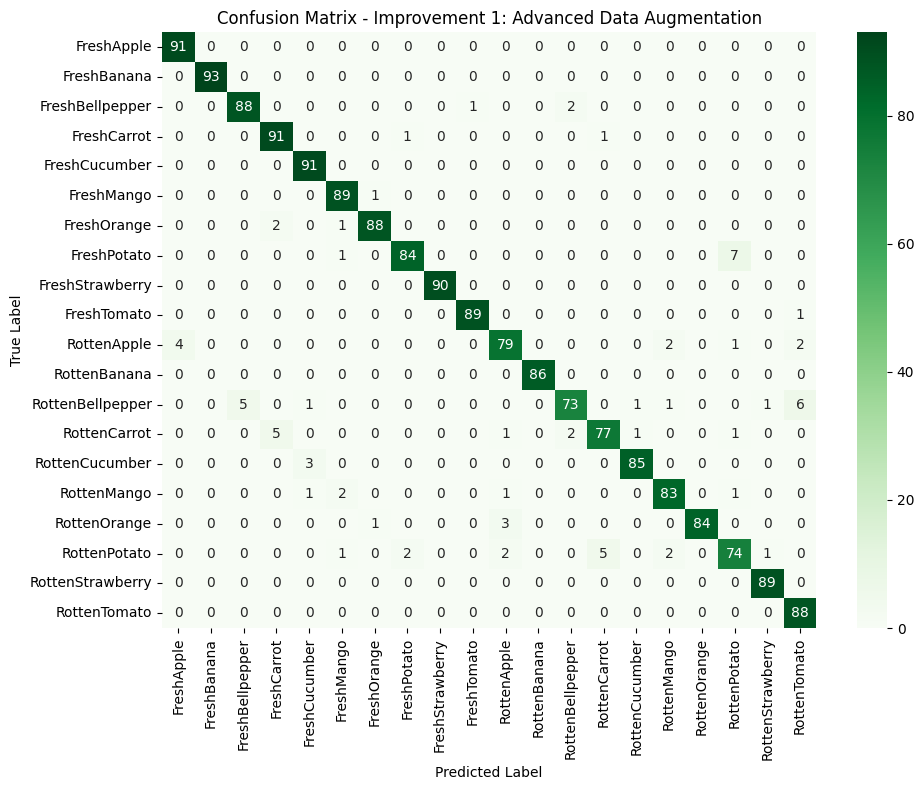

Validation Accuracy: 0.9570


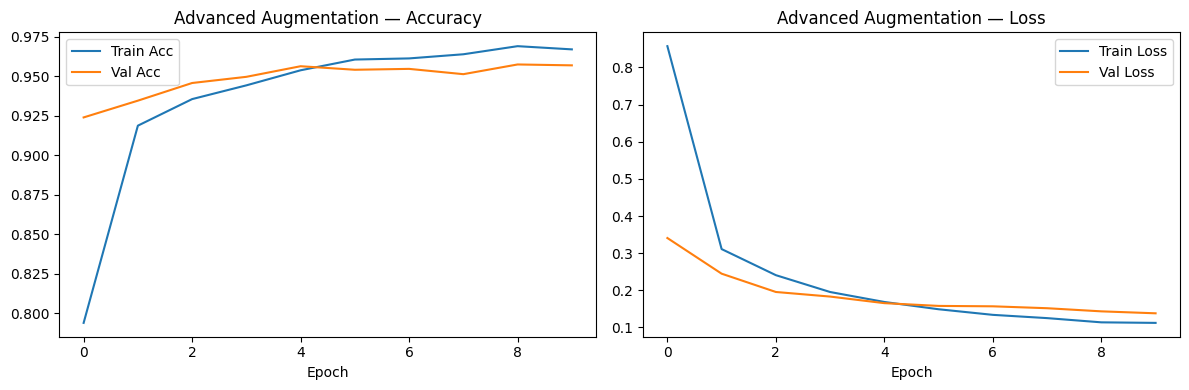

In [ ]:
# Evaluate Improvement 1 on Validation Set

results_aug = evaluate_on_val(aug_model, val_gen, model_name="Improvement 1: Advanced Data Augmentation")
# Plot training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(aug_history.history['accuracy'],     label='Train Acc')
plt.plot(aug_history.history['val_accuracy'], label='Val Acc')
plt.title('Advanced Augmentation — Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(aug_history.history['loss'],     label='Train Loss')
plt.plot(aug_history.history['val_loss'], label='Val Loss')
plt.title('Advanced Augmentation — Loss'); plt.xlabel('Epoch'); plt.legend()

plt.tight_layout()
plt.show()

---
## Improvement 2: Cosine Learning Rate Schedule

**What it is:**  
In this improvement, the fixed learning rate (0.001) is replaced with a Cosine Decay schedule.
The learning rate starts at 0.001 and smoothly decreases following a cosine curve
down to near zero by the end of training.

**Why it is used:**  
A fixed learning rate can cause the optimizer to oscillate around the minimum in later epochs
without settling into it. Cosine decay starts aggressive (high LR for fast early learning)
and gradually becomes fine-grained (low LR for precise convergence), which typically produces
better final accuracy and a smoother loss curve.

**What it changes:**  
Only the optimizer's learning rate changes — from a fixed scalar `0.001`
to a `CosineDecay` schedule object. The model architecture, loss function,
and all other settings remain identical to the baseline.

| Setting | Baseline | This Improvement |
|---|---|---|
| Learning Rate | Fixed: 0.001 | Cosine Decay: 0.001 → ~0 |
| Optimizer | Adam | Adam (with schedule) |
| Architecture | Baseline | Baseline (unchanged) |
| Loss | Categorical CE | Categorical CE |


In [ ]:
# Improvement 2: Cosine Learning Rate Schedule

# Build a fresh baseline model (same architecture as baseline)
cosine_model = create_effnetb0_baseline(num_classes)

# Define cosine decay schedule
# decay_steps = steps_per_epoch * total_epochs
steps_per_epoch = train_gen.samples // train_gen.batch_size
total_epochs    = 10
decay_steps     = steps_per_epoch * total_epochs

cosine_lr = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.001,  # same starting LR as baseline
    decay_steps=decay_steps,
    alpha=1e-6                    # minimum LR at end of decay
)

# Compile with cosine schedule — only change from baseline
cosine_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=cosine_lr),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(f"Steps per epoch : {steps_per_epoch}")
print(f"Total decay steps: {decay_steps}")
cosine_model.summary()

Steps per epoch : 261
Total decay steps: 2610


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# Train Improvement 2

cosine_history = cosine_model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    verbose=1
)

Epoch 1/10
 50/262 ━━━━━━━━━━━━━━━━━━━━ 1:35 451ms/step - accuracy: 0.3086 - loss: 2.4438

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


262/262 ━━━━━━━━━━━━━━━━━━━━ 172s 573ms/step - accuracy: 0.7898 - loss: 0.8525 - val_accuracy: 0.9189 - val_loss: 0.3418
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 127s 483ms/step - accuracy: 0.9198 - loss: 0.3136 - val_accuracy: 0.9374 - val_loss: 0.2439
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 125s 478ms/step - accuracy: 0.9404 - loss: 0.2324 - val_accuracy: 0.9475 - val_loss: 0.2073
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 128s 486ms/step - accuracy: 0.9534 - loss: 0.1898 - val_accuracy: 0.9463 - val_loss: 0.1915
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 130s 493ms/step - accuracy: 0.9538 - loss: 0.1723 - val_accuracy: 0.9514 - val_loss: 0.1759
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 139s 482ms/step - accuracy: 0.9597 - loss: 0.1554 - val_accuracy: 0.9530 - val_loss: 0.1734
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 127s 482ms/step - accuracy: 0.9596 - loss: 0.1498 - val_accuracy: 0.9536 - val_loss: 0.1698
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 130s 495ms/step - accuracy: 0.9640 - loss: 0.14

56/56 ━━━━━━━━━━━━━━━━━━━━ 21s 256ms/step

Improvement 2: Cosine LR Schedule
                  precision    recall  f1-score   support

      FreshApple       0.95      1.00      0.97        91
     FreshBanana       1.00      1.00      1.00        93
 FreshBellpepper       0.95      0.97      0.96        91
     FreshCarrot       0.92      0.98      0.95        93
   FreshCucumber       0.95      0.98      0.96        91
      FreshMango       0.97      0.99      0.98        90
     FreshOrange       0.98      0.97      0.97        91
     FreshPotato       0.96      0.95      0.95        92
 FreshStrawberry       1.00      1.00      1.00        90
     FreshTomato       0.99      0.99      0.99        90
     RottenApple       0.91      0.89      0.90        88
    RottenBanana       1.00      1.00      1.00        86
RottenBellpepper       0.99      0.82      0.89        88
    RottenCarrot       0.95      0.89      0.92        87
  RottenCucumber       0.94      0.95      0.95     

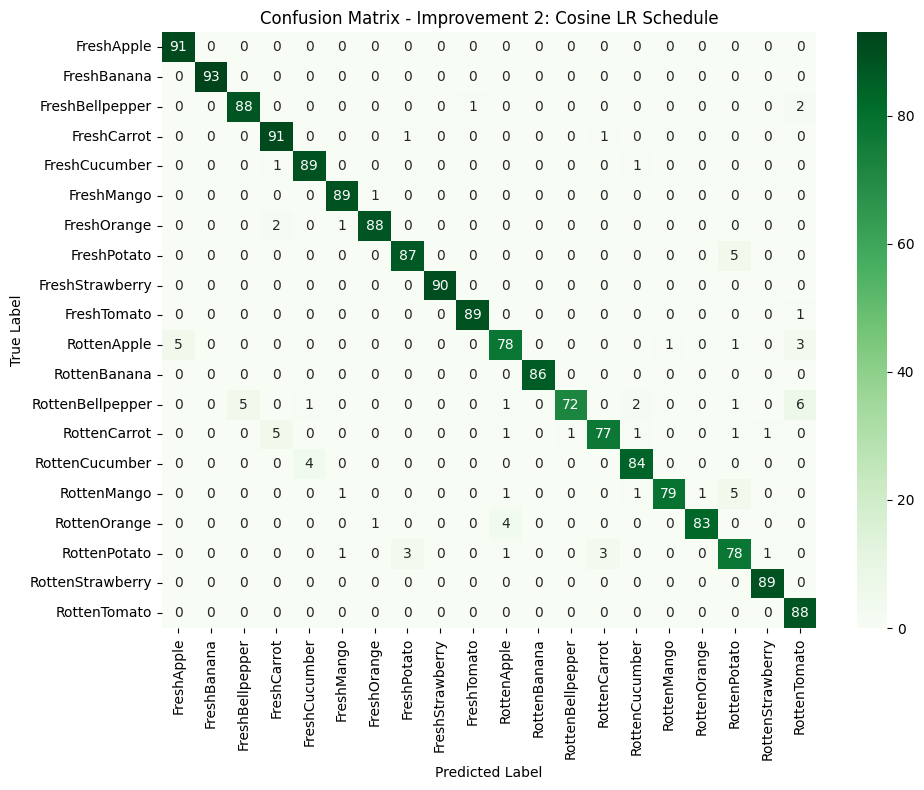

Validation Accuracy: 0.9553


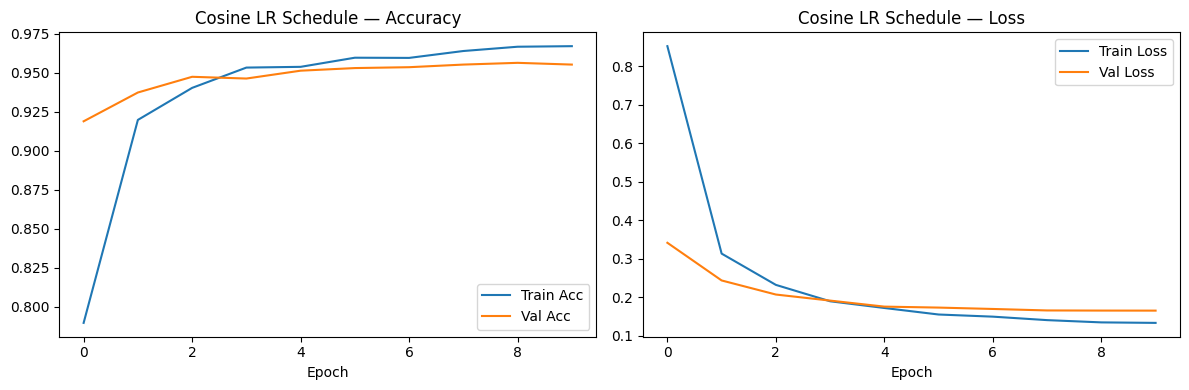

In [ ]:
# Evaluate Improvement 2 on Validation Set

results_cosine = evaluate_on_val(cosine_model, val_gen, model_name="Improvement 2: Cosine LR Schedule")

# Plot training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(cosine_history.history['accuracy'],     label='Train Acc')
plt.plot(cosine_history.history['val_accuracy'], label='Val Acc')
plt.title('Cosine LR Schedule — Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cosine_history.history['loss'],     label='Train Loss')
plt.plot(cosine_history.history['val_loss'], label='Val Loss')
plt.title('Cosine LR Schedule — Loss'); plt.xlabel('Epoch'); plt.legend()

plt.tight_layout()
plt.show()

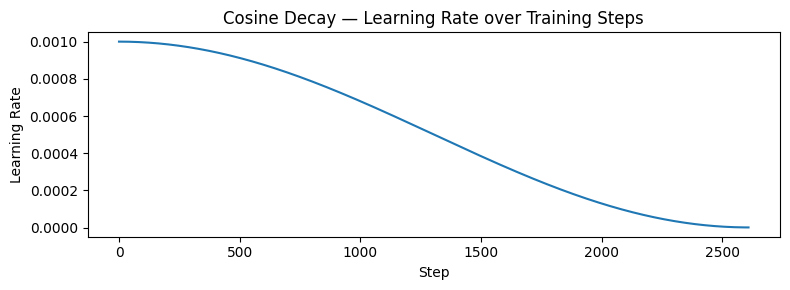

In [ ]:
# Visualize the cosine decay curve
import numpy as np
import matplotlib.pyplot as plt

lr_values = []
for step in range(decay_steps):
    completed = step / decay_steps
    cosine_val = 0.5 * (1 + np.cos(np.pi * completed))
    lr = 1e-6 + (0.001 - 1e-6) * cosine_val
    lr_values.append(lr)

plt.figure(figsize=(8, 3))
plt.plot(lr_values)
plt.title('Cosine Decay — Learning Rate over Training Steps')
plt.xlabel('Step'); plt.ylabel('Learning Rate')
plt.tight_layout()
plt.show()

---
## Improvement 3: MixUp Augmentation

**What it is:**  
MixUp is a data augmentation technique that creates new training samples by blending two images
and their labels together using a random mixing coefficient λ (lambda):
λ is sampled from a Beta distribution: `λ ~ Beta(alpha, alpha)`, where `alpha=0.2`.

**Why it is used:**  
Standard augmentation (rotation, flip, zoom) only modifies a single image at a time.
MixUp forces the model to behave linearly between training examples, which:
- Reduces overconfidence (the model learns soft boundaries between classes)
- Acts as an additional regularizer on top of L2 and Label Smoothing
- Improves generalization, especially when training data is limited

**What it changes:**  
A custom `mixup_generator()` wraps the existing `train_gen` and blends batches on-the-fly.
The model architecture, optimizer, loss, and all other settings remain identical to the baseline.

| Setting | Baseline | This Improvement |
|---|---|---|
| Architecture | Baseline | Baseline (unchanged) |
| Optimizer | Adam 0.001 | Adam 0.001 |
| Loss | Categorical CE | Categorical CE |
| Augmentation | Standard | Standard + MixUp |
| MixUp alpha | — | 0.2 |

In [ ]:
def mixup_generator(generator, alpha=0.2):
    while True:
        X1, y1 = next(generator)
        X2, y2 = next(generator)

        batch_size = min(len(X1), len(X2))
        X1, y1 = X1[:batch_size], y1[:batch_size]
        X2, y2 = X2[:batch_size], y2[:batch_size]

        lam = np.random.beta(alpha, alpha, size=(batch_size, 1, 1, 1))

        X_mixed = lam * X1 + (1 - lam) * X2
        y_mixed = lam.reshape(batch_size, 1) * y1 + (1 - lam.reshape(batch_size, 1)) * y2

        yield X_mixed, y_mixed

In [ ]:
mixup_model = create_effnetb0_baseline(num_classes)

mixup_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

mixup_train_gen = mixup_generator(train_gen, alpha=0.2)
steps_per_epoch_mixup = train_gen.samples // train_gen.batch_size

print(f"MixUp alpha       : 0.2")
print(f"Steps per epoch   : {steps_per_epoch_mixup}")
mixup_model.summary()

MixUp alpha       : 0.2
Steps per epoch   : 261


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
mixup_history = mixup_model.fit(
    mixup_train_gen,
    steps_per_epoch=steps_per_epoch_mixup,
    epochs=10,
    validation_data=val_gen,
    verbose=1
)

Epoch 1/10
 15/261 ━━━━━━━━━━━━━━━━━━━━ 3:48 930ms/step - accuracy: 0.1158 - loss: 2.9291

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


261/261 ━━━━━━━━━━━━━━━━━━━━ 306s 1s/step - accuracy: 0.7240 - loss: 1.2846 - val_accuracy: 0.9201 - val_loss: 0.4084
Epoch 2/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 277s 1s/step - accuracy: 0.8549 - loss: 0.8601 - val_accuracy: 0.9357 - val_loss: 0.3052
Epoch 3/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 256s 983ms/step - accuracy: 0.8823 - loss: 0.7816 - val_accuracy: 0.9435 - val_loss: 0.2638
Epoch 4/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accuracy: 0.8851 - loss: 0.7766 - val_accuracy: 0.9435 - val_loss: 0.2485
Epoch 5/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.8959 - loss: 0.7420 - val_accuracy: 0.9463 - val_loss: 0.2319
Epoch 6/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 258s 993ms/step - accuracy: 0.8957 - loss: 0.7359 - val_accuracy: 0.9469 - val_loss: 0.2247
Epoch 7/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 260s 1s/step - accuracy: 0.9025 - loss: 0.7206 - val_accuracy: 0.9497 - val_loss: 0.2179
Epoch 8/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 259s 995ms/step - accuracy: 0.9066 - loss: 0.7064 - val_accura

56/56 ━━━━━━━━━━━━━━━━━━━━ 21s 254ms/step

Improvement 6: MixUp Augmentation
                  precision    recall  f1-score   support

      FreshApple       0.97      0.97      0.97        91
     FreshBanana       1.00      1.00      1.00        93
 FreshBellpepper       0.95      0.97      0.96        91
     FreshCarrot       0.94      0.98      0.96        93
   FreshCucumber       0.96      0.99      0.97        91
      FreshMango       0.96      0.99      0.97        90
     FreshOrange       0.98      0.98      0.98        91
     FreshPotato       0.96      0.92      0.94        92
 FreshStrawberry       1.00      1.00      1.00        90
     FreshTomato       0.98      0.99      0.98        90
     RottenApple       0.86      0.94      0.90        88
    RottenBanana       1.00      1.00      1.00        86
RottenBellpepper       0.95      0.83      0.88        88
    RottenCarrot       0.94      0.84      0.88        87
  RottenCucumber       0.97      0.94      0.95     

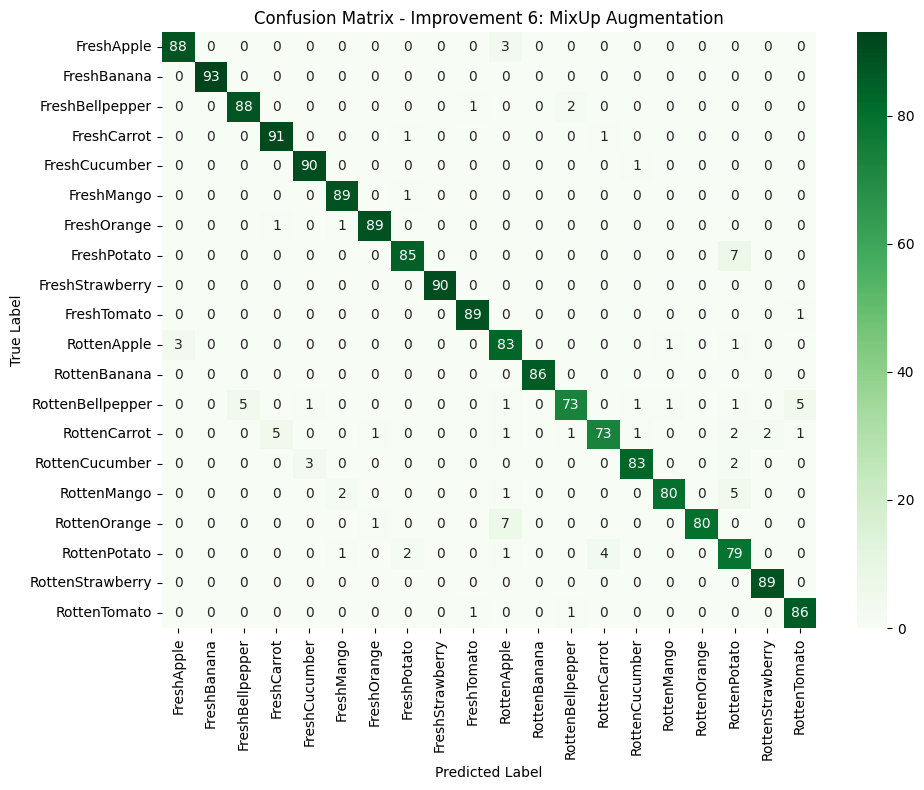

Validation Accuracy: 0.9525


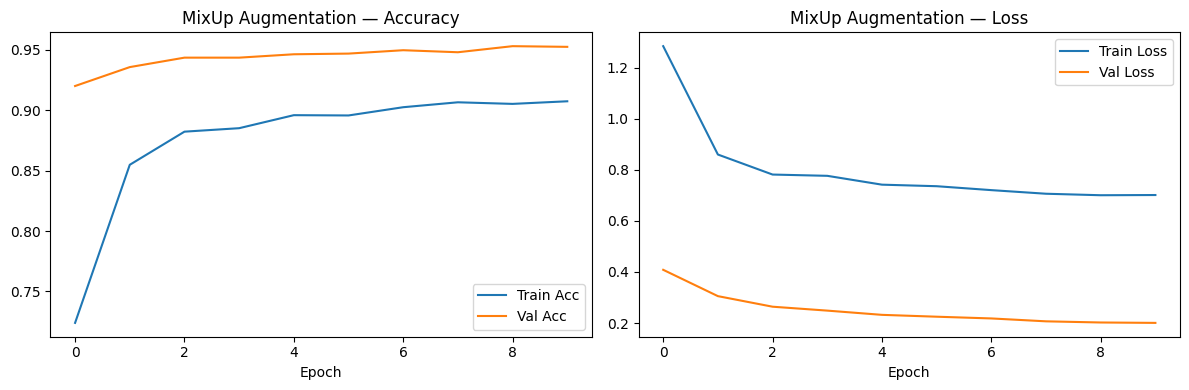

In [ ]:
results_mixup = evaluate_on_val(mixup_model, val_gen, model_name="Improvement 3: MixUp Augmentation")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(mixup_history.history['accuracy'],     label='Train Acc')
plt.plot(mixup_history.history['val_accuracy'], label='Val Acc')
plt.title('MixUp Augmentation — Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mixup_history.history['loss'],     label='Train Loss')
plt.plot(mixup_history.history['val_loss'], label='Val Loss')
plt.title('MixUp Augmentation — Loss'); plt.xlabel('Epoch'); plt.legend()

plt.tight_layout()
plt.show()

# Experiment Set D: Focal Loss & AdamW
This section contains three model improvement experiments, each tested on the validation set to evaluate their individual and combined impact.

### Implemented Improvements:
1. **Focal Loss**: Replaces standard Cross-Entropy to force the model to focus on hard-to-classify and borderline examples.
2. **AdamW Optimizer**: Introduces decoupled weight decay to improve model generalization and mitigate overfitting.
3. **Combined Approach (Focal Loss + AdamW)**: Integrates both the customized loss function and the advanced optimizer to achieve the highest possible accuracy and stability.

All improvements are compared directly with the baseline model under the exact same training and evaluation conditions.

In [ ]:
import tensorflow as tf

# Load the baseline model directly
#baseline_model = tf.keras.models.load_model('effnetb0_baseline_model.keras')

# Evaluate the model directly on validation data
#baseline_loss, baseline_accuracy = baseline_model.evaluate(val_gen)
#print(f"Baseline Accuracy: {baseline_accuracy * 100:.2f}%")

In [ ]:
# Define the baseline model creation function exactly as requested
def create_effnetb0_baseline(num_classes, input_shape=(224, 224, 3)):
    # Load pretrained EfficientNetB0
    # include_top=False removes the original classifier head
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )

    # Freeze the base model to prevent training
    base_model.trainable = False

    # Build classification head
    model = models.Sequential([
        base_model,                         # feature extractor
        layers.GlobalAveragePooling2D(),    # convert features to vector
        layers.Dropout(0.2),                # reduce overfitting
        layers.Dense(num_classes, activation="softmax")  # output layer
    ])

    return model

In [ ]:
import tensorflow as tf

# ==========================================
# 0. Optimization Settings
# ==========================================
# Define Focal Loss to address difficult and imbalanced images
focal_loss = tf.keras.losses.CategoricalFocalCrossentropy(alpha=0.25, gamma=2.0)

# Define AdamW Optimizer for decoupled Weight Decay
optimizer_adamw = tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004)

# (Define number of training epochs)
EPOCHS = 10

## Improvement 1: Focal Loss

**What it is:** In this improvement, the standard Categorical Cross-Entropy loss is replaced with Categorical Focal Cross-Entropy (using focusing parameter $\gamma = 2.0$ and $\alpha = 0.25$).

**Why it is used:** Standard Cross-Entropy gives equal weight to all samples, which means the model spends too much time learning from "easy" examples (like an obviously completely rotten apple). Focal loss dynamically scales the loss based on prediction confidence, down-weighting easy examples and forcing the model to focus its training heavily on hard, borderline cases (like a strawberry with a microscopic bruise). This improves the model's recall on difficult classes.

**What it changes:** Only the loss function changes — from `categorical_crossentropy` to a `CategoricalFocalCrossentropy` object. The model architecture, optimizer, and all other settings remain identical to the baseline.

| Setting | Baseline | This Improvement |
| --- | --- | --- |
| Loss Function | Categorical CE | Categorical Focal CE ($\gamma=2.0$) |
| Optimizer | Adam | Adam (unchanged) |
| Learning Rate | Fixed: 0.001 | Fixed: 0.001 (unchanged) |
| Architecture | Baseline | Baseline (unchanged) |

---

In [ ]:
# ==========================================
# Experiment 1: Cost Function Improvement (Focal Loss)
# ==========================================
print(" Starting training for Experiment 1 (Focal Loss)...")

# Create a new and clean instance of the baseline model
model_exp1 = create_effnetb0_baseline(num_classes)
model_exp1.summary()

# Compile the model with the first improvement
model_exp1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # Baseline
    loss=focal_loss,
    metrics=["accuracy"]
)

# Start training
history_exp1 = model_exp1.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS
)
print(" Experiment 1 training finished successfully!")

 Starting training for Experiment 1 (Focal Loss)...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 47s 125ms/step - accuracy: 0.8143 - loss: 0.1191 - val_accuracy: 0.9340 - val_loss: 0.0328
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 112ms/step - accuracy: 0.9390 - loss: 0.0271 - val_accuracy: 0.9480 - val_loss: 0.0210
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 112ms/step - accuracy: 0.9538 - loss: 0.0177 - val_accuracy: 0.9580 - val_loss: 0.0170
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 111ms/step - accuracy: 0.9650 - loss: 0.0130 - val_accuracy: 0.9608 - val_loss: 0.0150
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 113ms/step - accuracy: 0.9702 - loss: 0.0102 - val_accuracy: 0.9591 - val_loss: 0.0139
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 111ms/step - accuracy: 0.9760 - loss: 0.0083 - val_accuracy: 0.9664 - val_loss: 0.0135
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - accuracy: 0.9773 - loss: 0.0072 - val_accuracy: 0.9675 - val_loss: 0.0122
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 111ms/step - accuracy: 0.9838 - loss: 0

## Improvement 2: AdamW Optimizer

**What it is:** In this improvement, the standard Adam optimizer is replaced with AdamW (Adam with decoupled Weight Decay), introducing a weight decay rate of 0.004.

**Why it is used:** In standard Adam, weight decay (L2 regularization) is mixed with the gradient update formulas, making it less effective. AdamW decouples the weight decay from the optimization steps, directly penalizing large weights. This leads to much better generalization on unseen validation data, smoother learning curves, and effectively mitigates overfitting without requiring extra epochs.

**What it changes:** Only the optimizer changes — from `Adam` to `AdamW`. The model architecture, loss function, and learning rate remain identical to the baseline.

| Setting | Baseline | This Improvement |
| --- | --- | --- |
| Optimizer | Adam | AdamW (Weight Decay=0.004) |
| Loss Function | Categorical CE | Categorical CE (unchanged) |
| Learning Rate | Fixed: 0.001 | Fixed: 0.001 (unchanged) |
| Architecture | Baseline | Baseline (unchanged) |

---

In [ ]:
# ==========================================
# Experiment 2: Optimizer Improvement (AdamW)
# ==========================================
print(" Starting training for Experiment 2 (AdamW)...")

# Create a new and clean instance of the baseline model
model_exp2 = create_effnetb0_baseline(num_classes)
model_exp2.summary()

# Compile the model with the second improvement
model_exp2.compile(
    optimizer=optimizer_adamw,
    loss="categorical_crossentropy",            # Baseline
    metrics=["accuracy"]
)

# Start training
history_exp2 = model_exp2.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS
)
print(" Experiment 2 training finished successfully!")

 Starting training for Experiment 2 (AdamW)...


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 43s 123ms/step - accuracy: 0.8063 - loss: 0.7920 - val_accuracy: 0.9261 - val_loss: 0.3206
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 113ms/step - accuracy: 0.9349 - loss: 0.2611 - val_accuracy: 0.9474 - val_loss: 0.2163
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 32s 121ms/step - accuracy: 0.9556 - loss: 0.1842 - val_accuracy: 0.9536 - val_loss: 0.1775
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 39s 114ms/step - accuracy: 0.9643 - loss: 0.1467 - val_accuracy: 0.9580 - val_loss: 0.1537
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 114ms/step - accuracy: 0.9710 - loss: 0.1205 - val_accuracy: 0.9625 - val_loss: 0.1394
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 112ms/step - accuracy: 0.9738 - loss: 0.1047 - val_accuracy: 0.9647 - val_loss: 0.1298
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 112ms/step - accuracy: 0.9790 - loss: 0.0890 - val_accuracy: 0.9653 - val_loss: 0.1228
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 29s 112ms/step - accuracy: 0.9807 - loss: 0

## Improvement 3: Combined Approach (Focal Loss + AdamW)

**What it is:** This experiment integrates both improvements simultaneously: applying the Categorical Focal Cross-Entropy loss alongside the AdamW optimizer.

**Why it is used:** To test whether combining advanced loss calculation with superior regularization yields a compounded benefit. Theoretically, while Focal Loss forces the model to aggressively learn hard examples, AdamW acts as a strict regularizer to ensure the model does not overfit to these difficult cases, aiming to find the ultimate balance between high recall and stability.

**What it changes:** Both the loss function and the optimizer are replaced. The base EfficientNetB0 architecture, data generators, and learning rate remain strictly identical to the baseline.

| Setting | Baseline | This Improvement |
| --- | --- | --- |
| Loss Function | Categorical CE | Categorical Focal CE ($\gamma=2.0$) |
| Optimizer | Adam | AdamW (Weight Decay=0.004) |
| Learning Rate | Fixed: 0.001 | Fixed: 0.001 (unchanged) |
| Architecture | Baseline | Baseline (unchanged) |

In [ ]:
# ==========================================
# Experiment 3: Combination (Focal Loss + AdamW)
# ==========================================
print(" Starting training for Experiment 3 (Combination)...")

# Create a new and clean instance of the baseline model
model_exp3 = create_effnetb0_baseline(num_classes)
model_exp3.summary()

# Create a new instance of AdamW optimizer for this model
optimizer_adamw_exp3 = tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004)

# Compile the model with the combined improvements
model_exp3.compile(
    optimizer=optimizer_adamw_exp3,
    loss=focal_loss,
    metrics=["accuracy"]
)

# Start training
history_exp3 = model_exp3.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS
)
print(" Experiment 3 training finished successfully!")

 Starting training for Experiment 3 (Combination)...


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 43s 122ms/step - accuracy: 0.8144 - loss: 0.1194 - val_accuracy: 0.9250 - val_loss: 0.0326
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 115ms/step - accuracy: 0.9390 - loss: 0.0271 - val_accuracy: 0.9463 - val_loss: 0.0212
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 114ms/step - accuracy: 0.9569 - loss: 0.0174 - val_accuracy: 0.9541 - val_loss: 0.0177
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 30s 116ms/step - accuracy: 0.9662 - loss: 0.0127 - val_accuracy: 0.9547 - val_loss: 0.0154
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 31s 116ms/step - accuracy: 0.9698 - loss: 0.0100 - val_accuracy: 0.9564 - val_loss: 0.0149
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 116ms/step - accuracy: 0.9773 - loss: 0.0081 - val_accuracy: 0.9603 - val_loss: 0.0133
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 114ms/step - accuracy: 0.9800 - loss: 0.0067 - val_accuracy: 0.9603 - val_loss: 0.0128
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 41s 114ms/step - accuracy: 0.9808 - loss: 0

## Evaluation

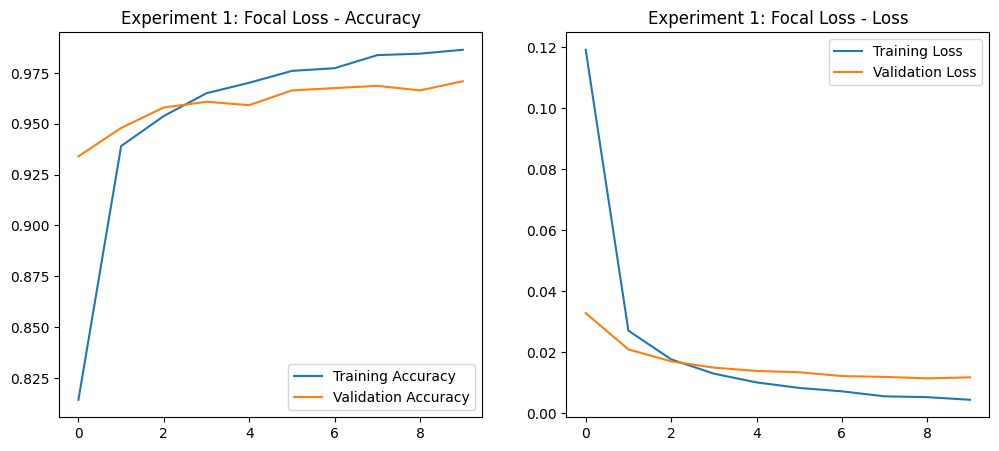

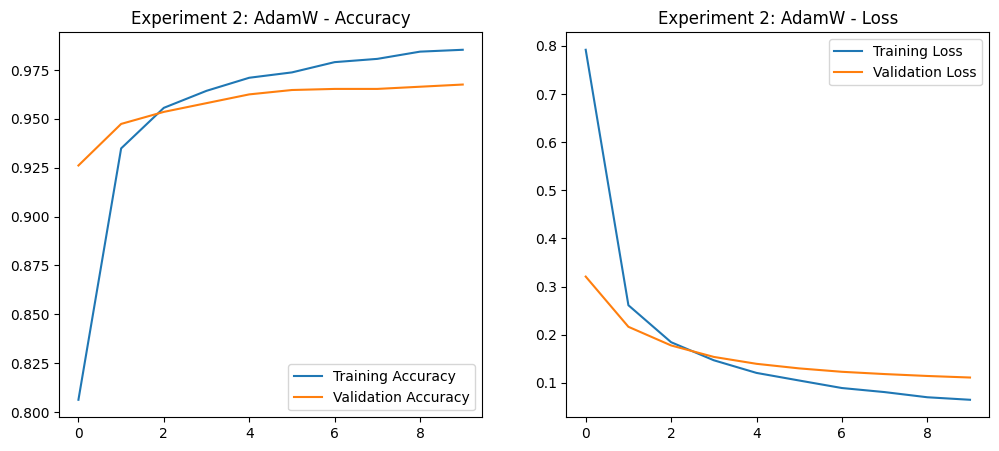

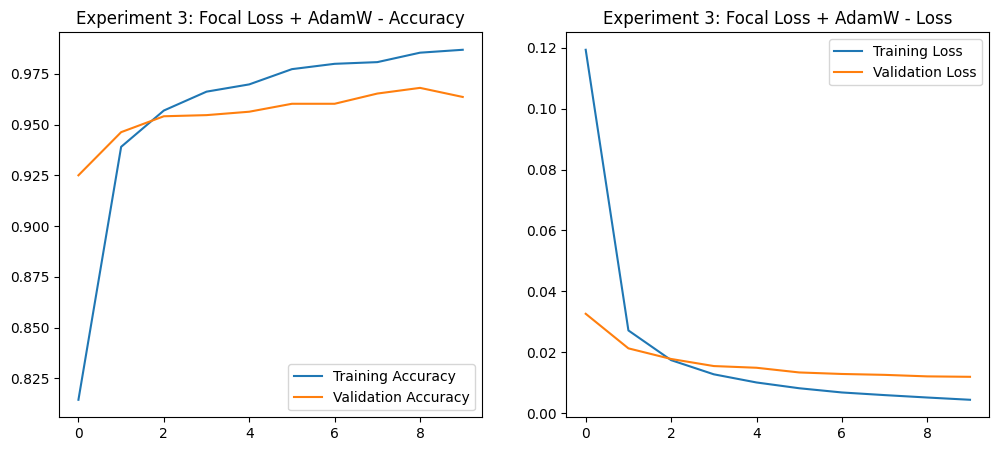

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))

    # Accuracy curve
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title(f'{title} - Accuracy')

    # Loss curve
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title(f'{title} - Loss')

    plt.show()

# Call the function for the three experiments
plot_training_history(history_exp1, "Experiment 1: Focal Loss")
plot_training_history(history_exp2, "Experiment 2: AdamW")
plot_training_history(history_exp3, "Experiment 3: Focal Loss + AdamW")

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model_performance(model, model_name):
    print("\n" + "="*60)
    print(f" Evaluating {model_name} and extracting predictions...")
    print("="*60)

    # For tf.data.Dataset, we need to iterate to get true labels and predictions
    y_true_list = []
    y_pred_list = []

    # Use the globally defined class_names list
    global class_names

    # Iterate through the validation dataset to get true labels and make predictions
    # Note: val_gen has shuffle=False, so order is preserved across iterations
    for images, labels in val_gen:
        preds = model.predict(images, verbose=0) # Predict batch by batch
        y_pred_list.extend(np.argmax(preds, axis=1))
        y_true_list.extend(np.argmax(labels.numpy(), axis=1)) # Convert one-hot labels to class indices

    y_true = np.array(y_true_list)
    y_pred_classes = np.array(y_pred_list)

    # 1. Print Classification Report (Precision, Recall, F1-Score)
    print(f"\n Classification Report - {model_name}\n")
    print(classification_report(y_true, y_pred_classes, target_names=class_names, digits=4))

    # 2. Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred_classes)

    plt.figure(figsize=(12, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=90)
    plt.show()


 Evaluating Experiment 1: Focal Loss and extracting predictions...

 Classification Report - Experiment 1: Focal Loss

                  precision    recall  f1-score   support

      FreshApple     1.0000    0.9780    0.9889        91
     FreshBanana     1.0000    1.0000    1.0000        93
 FreshBellpepper     0.9565    0.9670    0.9617        91
     FreshCarrot     0.9468    0.9570    0.9519        93
   FreshCucumber     0.9891    1.0000    0.9945        91
      FreshMango     0.9890    1.0000    0.9945        90
     FreshOrange     0.9783    0.9890    0.9836        91
     FreshPotato     0.9785    0.9891    0.9838        92
 FreshStrawberry     1.0000    1.0000    1.0000        90
     FreshTomato     1.0000    0.9778    0.9888        90
     RottenApple     0.9318    0.9425    0.9371        87
    RottenBanana     1.0000    0.9884    0.9942        86
RottenBellpepper     0.9121    0.9432    0.9274        88
    RottenCarrot     0.9412    0.9302    0.9357        86
  RottenC

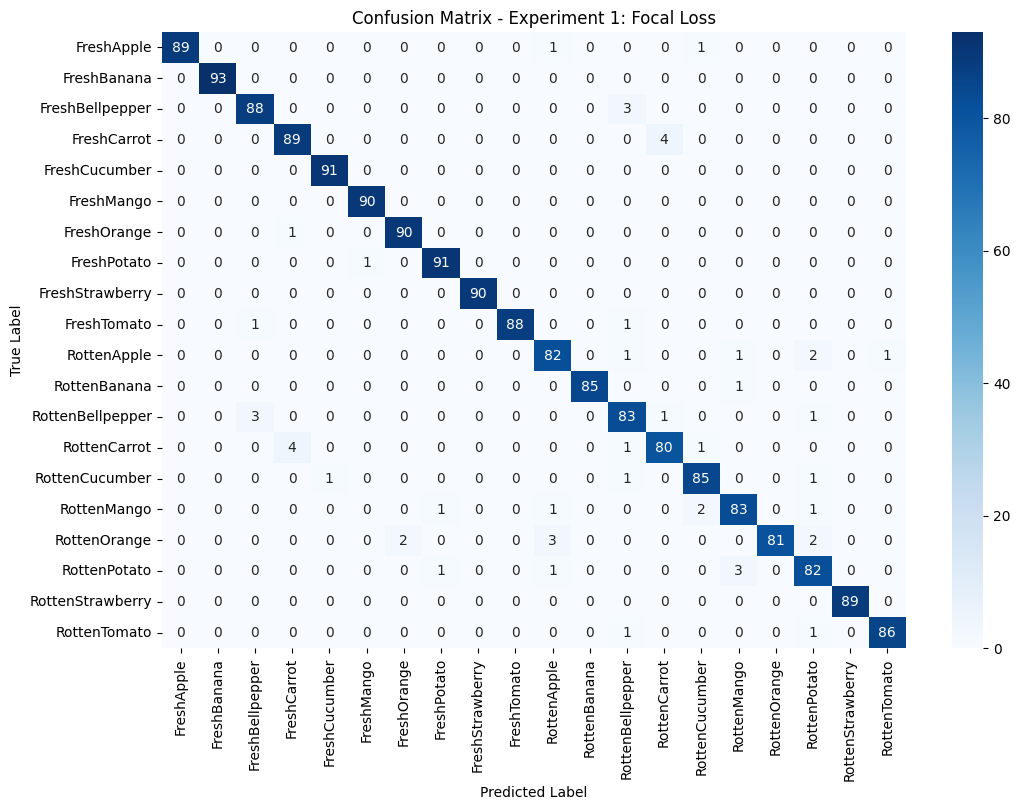


 Evaluating Experiment 2: AdamW and extracting predictions...

 Classification Report - Experiment 2: AdamW

                  precision    recall  f1-score   support

      FreshApple     0.9890    0.9890    0.9890        91
     FreshBanana     1.0000    1.0000    1.0000        93
 FreshBellpepper     0.9175    0.9780    0.9468        91
     FreshCarrot     0.9286    0.9785    0.9529        93
   FreshCucumber     0.9681    1.0000    0.9838        91
      FreshMango     0.9889    0.9889    0.9889        90
     FreshOrange     0.9677    0.9890    0.9783        91
     FreshPotato     0.9681    0.9891    0.9785        92
 FreshStrawberry     1.0000    1.0000    1.0000        90
     FreshTomato     1.0000    0.9778    0.9888        90
     RottenApple     0.9524    0.9195    0.9357        87
    RottenBanana     1.0000    0.9884    0.9942        86
RottenBellpepper     0.9529    0.9205    0.9364        88
    RottenCarrot     0.9750    0.9070    0.9398        86
  RottenCucumber   

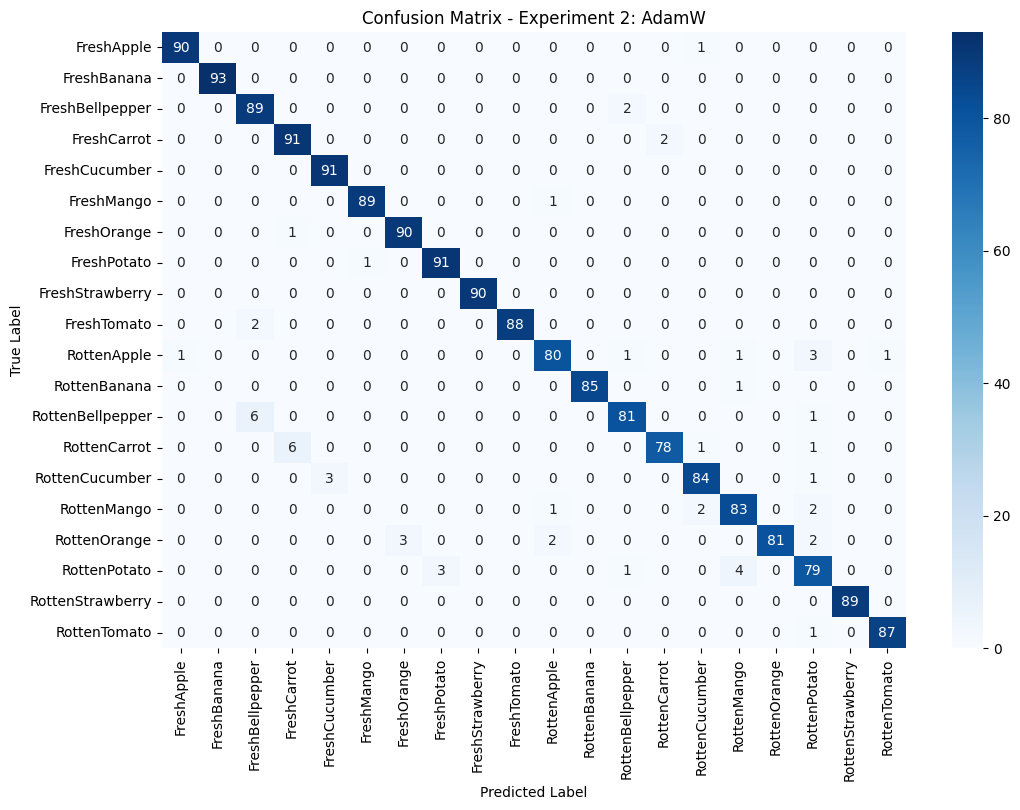


 Evaluating Experiment 3: Focal Loss + AdamW and extracting predictions...

 Classification Report - Experiment 3: Focal Loss + AdamW

                  precision    recall  f1-score   support

      FreshApple     0.9780    0.9780    0.9780        91
     FreshBanana     1.0000    1.0000    1.0000        93
 FreshBellpepper     0.9167    0.9670    0.9412        91
     FreshCarrot     0.9286    0.9785    0.9529        93
   FreshCucumber     0.9579    1.0000    0.9785        91
      FreshMango     0.9886    0.9667    0.9775        90
     FreshOrange     0.9783    0.9890    0.9836        91
     FreshPotato     0.9785    0.9891    0.9838        92
 FreshStrawberry     1.0000    0.9889    0.9944        90
     FreshTomato     1.0000    0.9556    0.9773        90
     RottenApple     0.9518    0.9080    0.9294        87
    RottenBanana     1.0000    0.9884    0.9942        86
RottenBellpepper     0.9294    0.8977    0.9133        88
    RottenCarrot     0.9750    0.9070    0.9398    

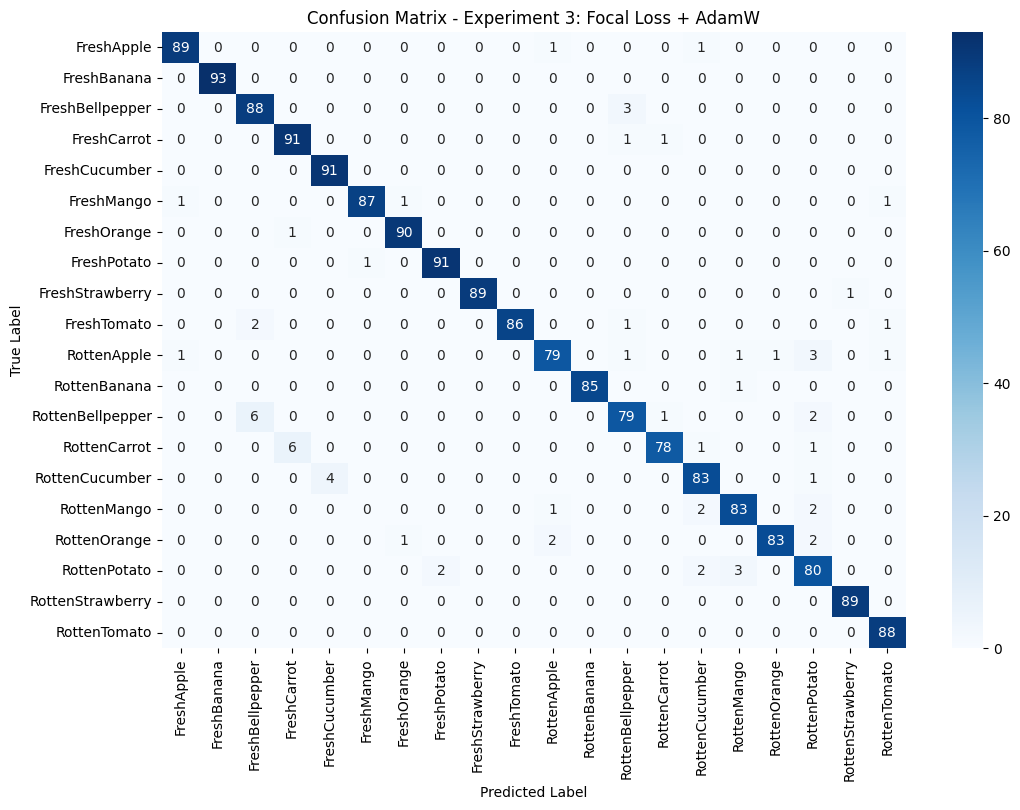

In [ ]:
# ==========================================
# Call the function to evaluate the three models
# ==========================================

# 1. Evaluate Experiment 1
evaluate_model_performance(model_exp1, "Experiment 1: Focal Loss")

# 2. Evaluate Experiment 2
evaluate_model_performance(model_exp2, "Experiment 2: AdamW")

# 3. Evaluate Experiment 3 (Combined)
evaluate_model_performance(model_exp3, "Experiment 3: Focal Loss + AdamW")

# Note: If you loaded (baseline) model, you can call the function for it in the same way:
#evaluate_model_performance(baseline_model, "Baseline Model")

# Results & Analysis

## Performance Comparison Summary

| Experiment | Loss Function | Optimizer | Val Accuracy |
| :--- | :--- | :--- | :--- |
| **Baseline Model** | Categorical CE | Adam | **97.09%** |
| **Exp 1: Focal Loss** | Categorical Focal CE | Adam | 97.09% |
| **Exp 2: AdamW** | Categorical CE | AdamW | 96.75% |
| **Exp 3: Combined** | Categorical Focal CE | AdamW | 96.36% |

## Key Observations

*   **Baseline & Focal Loss Parity:** The Baseline model and Experiment 1 (Focal Loss) achieved identical validation accuracy of 97.09%. This suggests that while Focal Loss is designed to handle hard examples, the current dataset's primary features were already captured effectively by the standard Cross-Entropy loss.
*   **Impact of AdamW:** Introducing AdamW in Experiment 2 led to a slight decrease in accuracy to 96.75% compared to the standard Adam optimizer used in the baseline. This indicates that the default weight decay settings in AdamW might be slightly over-regularizing the model for this specific task and epoch count.
*   **Combined Approach Performance:** Experiment 3, which combined Focal Loss and AdamW, resulted in the lowest accuracy among the tested improvements at 96.36%. The combination of focused loss and decoupled weight decay appears to have introduced too much regularization, preventing the model from reaching the peak performance seen in the baseline.
*   **Performance Ceiling:** Across all experiments, the accuracy remains very high (above 96%), confirming that the EfficientNetB0 backbone is highly robust for fruit and vegetable freshness classification, even with varying optimization strategies.

#MODEL TEST


Evaluating model and generating predictions...

Classification Report:
                  precision    recall  f1-score   support

      FreshApple     0.9785    0.9785    0.9785        93
     FreshBanana     0.9691    0.9895    0.9792        95
 FreshBellpepper     0.9670    0.9462    0.9565        93
     FreshCarrot     0.9783    0.9677    0.9730        93
   FreshCucumber     0.9388    1.0000    0.9684        92
      FreshMango     0.9783    0.9783    0.9783        92
     FreshOrange     0.9787    1.0000    0.9892        92
     FreshPotato     0.9451    0.9247    0.9348        93
 FreshStrawberry     1.0000    1.0000    1.0000        91
     FreshTomato     0.9888    0.9565    0.9724        92
     RottenApple     0.9043    0.9770    0.9392        87
    RottenBanana     0.9884    0.9770    0.9827        87
RottenBellpepper     0.9213    0.9111    0.9162        90
    RottenCarrot     0.9762    0.9425    0.9591        87
  RottenCucumber     0.9545    0.9333    0.9438        90


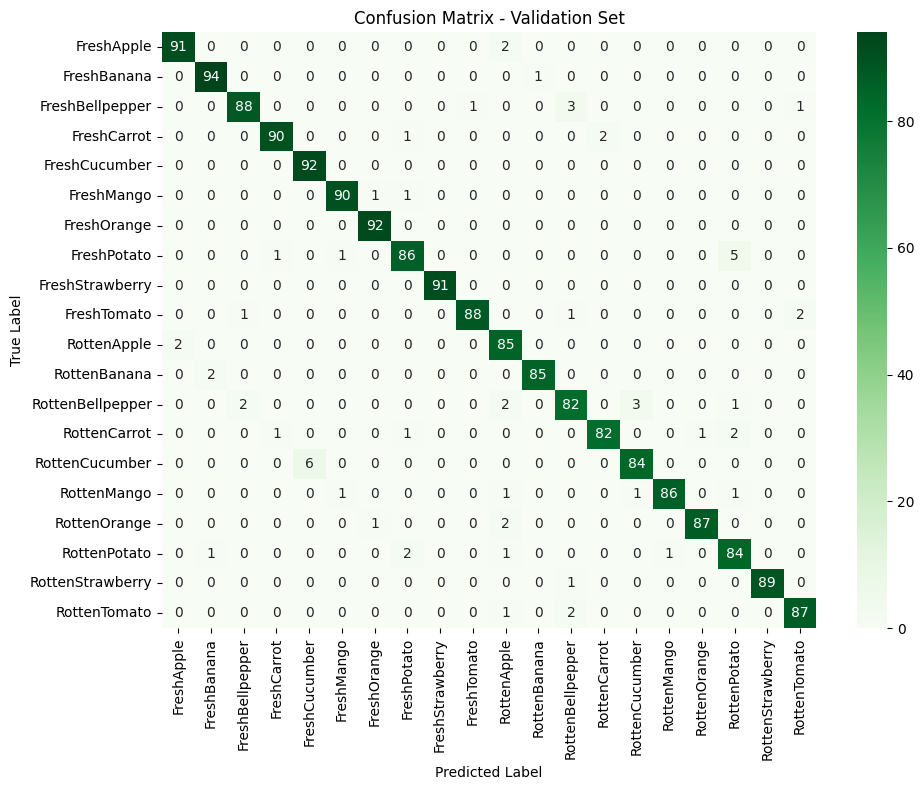

In [ ]:
# Final evaluation of the best-performing model on the unseen test set
evaluate("/content/drive/MyDrive/effnetb0_baseline_model.keras", test_gen, class_names)